# 1 Exploração dos Dados

&nbsp;&nbsp;&nbsp;&nbsp; Nesta etapa, foi realizada uma análise exploratória detalhada dos dados, com o objetivo de compreender as principais características das variáveis e suas relações. O processo seguiu as seguintes etapas:

### 1.1 Importação de Bibliotecas Necessárias

&nbsp;&nbsp;&nbsp;&nbsp; No código abaixo, são importadas as principais bibliotecas utilizadas para o tratamento de dados e a criação de gráficos, como Numpy, Pandas, Matplotlib, Seaborn e Scikit-Learn.

In [27]:
# Importar pacotes

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from flaml import AutoML
from sklearn.preprocessing import StandardScaler, OneHotEncoder,  MinMaxScaler, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, classification_report, precision_recall_fscore_support)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.over_sampling import SMOTE
from sklearn.utils.multiclass import unique_labels
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import lightgbm as lgb



### 1.2 Importação das Planilhas de Dados

&nbsp;&nbsp;&nbsp;&nbsp; O código abaixo importa as planilhas disponibilizadas pela empresa parceira Finnet.

In [28]:
# Carregar os arquivos CSV


# Carregamento em amostras para economia de memória e testes

df_gl = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GL.csv", sep="\t", header=0, engine="python")
df_gm = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GM.csv", sep="\t", header=0, engine="python")
df_gp = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GP.csv", sep="\t", header=0, engine="python")
df_gf = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GF.csv", sep="\t", header=0, engine="python")
df_gt = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GT.csv", sep="\t", header=0, engine="python")
df_gv = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GV.csv", sep="\t", header=0, engine="python")
df_gw = pd.read_csv("../Grupo com registro entre 07-2024 a 06-2025- GW.csv", sep="\t", header=0, engine="python")

# Após carregar, conversão de floats para float32 para economizar memória também

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    for col in df.select_dtypes(include="float64").columns:
        df[col] = df[col].astype("float32")


 ### 1.3 Divisão de Colunas em Múltiplas Colunas

&nbsp;&nbsp;&nbsp;&nbsp; Após importar os arquivos CSV, todas as informações vieram concentradas em uma única coluna. Para resolver isso, foi criada uma função que divide corretamente os valores em múltiplas colunas, utiliza a primeira linha como cabeçalho e retorna o DataFrame ajustado. Essa função foi aplicada em todos os Dataframes.

In [29]:
# Função para a divisão das colunas

def dividir_colunas(df):

    # Verifica se o DataFrame tem apenas uma coluna.

    if df.shape[1] == 1:

        # Divide a única coluna em múltiplas colunas.

        dados = df.iloc[:, 0].str.split('\t', expand=True)

        # Usa a primeira linha como nomes das colunas.

        dados.columns = dados.iloc[0]

        # Remove a primeira linha por ter virado cabeçalho.

        dados = dados.drop(index=0).reset_index(drop=True)
        return dados
    else:

        return df

df_gf = dividir_colunas(df_gf)
df_gl = dividir_colunas(df_gl)
df_gm = dividir_colunas(df_gm)
df_gp = dividir_colunas(df_gp)
df_gt = dividir_colunas(df_gt)
df_gv = dividir_colunas(df_gv)
df_gw = dividir_colunas(df_gw)

### 1.4 Conversão de Tipos de Dados


&nbsp;&nbsp;&nbsp;&nbsp; Esse código é responsável por padronizar os tipos de dados das colunas de diferentes DataFrames após a importação. Primeiro, ele organiza as colunas em quatro grupos: numéricas, categóricas, de datas e de texto. Em seguida, a função converter_tipos percorre cada grupo e faz os ajustes necessários. Para as colunas numéricas, substitui valores inválidos representados por \N por NaN e converte os dados para tipo numérico. Para as colunas categóricas, altera o tipo para category, o que facilita análises e economiza memória. Já nas colunas de datas, também substitui \N por NaN e converte para o formato datetime, permitindo operações temporais como filtragem e cálculos.

In [30]:
# Divisão de tipos

colunas_numericas = ['multa','id_grupo', 'id_pagador', 'id_beneficiario', 'Numero_do_boleto', 'vl_boleto', 'vl_pagto', 'juros']
colunas_categoricas = ['tipo_multa', 'status_boleto', 'pagador_cep', 'banco', 'tipo_juros', 'pagador_cidade']
colunas_data = ['data_inclusao', 'data_vencto', 'dt_pagto', 'pagador_dt_ultimo_acesso ']
colunas_texto = [ 'pagador_cnpjcpf', 'pagador_inscricao_hash']

# Função para converter em um DataFrame

def converter_tipos(df):

    # Converte colunas numéricas para tipo numérico, formatando '\N' como NaN

    for col in colunas_numericas:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')

    # Converte colunas categóricas para category

    for col in colunas_categoricas:
        if col in df.columns:
            df[col] = df[col].astype('category')

    # Converte colunas de data para tipo datetime, formatando '\N' como NaN

    for col in colunas_data:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col].replace('\\N', np.nan), errors='coerce')

# Aplica a função de conversão de tipos para cada DataFrame

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    converter_tipos(df)

C:\Users\Inteli\AppData\Local\Temp\ipykernel_33268\201677261.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')
C:\Users\Inteli\AppData\Local\Temp\ipykernel_33268\201677261.py:16: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = pd.to_numeric(df[col].replace('\\N', np.nan), errors='coerce')


## 1.5 Tratamento de Valores Ausentes

O código abaixo passa por todos os dataframes e remove valores ausentes das colunas 'vl_pagto', 'multa' e 'qtd_acessos_pagador' e substitui esses valores por 0.

In [31]:
# Colunas para remoção considerando que tem muitos valores ausentes

# colunas_para_remover = ['tipo_multa', 'multa']

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:

    # df.drop(columns=[c for c in colunas_para_remover if c in df.columns], inplace=True)

    # Substitui valores ausentes em colunas numéricas por 0

    colunas_ausentes = ['vl_pagto', 'multa', 'qtd_acessos_pagador']

    for coluna in colunas_ausentes:
        if coluna in df.columns:
            df[coluna] = df[coluna].fillna(0)

    # Trata valores ausentes em pagador_cidade

    if 'pagador_cidade' in df.columns:
        df['pagador_cidade'] = df['pagador_cidade'].cat.add_categories('Desconhecido')
        df['pagador_cidade'] = df['pagador_cidade'].fillna('Desconhecido')


## 1.6 Identificação e Tratamento de Outliers


Esse código percorre várias tabelas e, nas colunas numéricas, identifica outliers pelo intervalo interquartil (IQR) e os substitui pelos limites mínimo e máximo aceitáveis, ajustando valores extremos sem excluir dados.

In [32]:
# Verificação em quartis

for df in [df_gf, df_gl, df_gm, df_gp, df_gt, df_gv, df_gw]:
    for col in colunas_numericas:
        if col in df.columns:

            # Quartis
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1

            # Limites
            lim_inf = Q1 - 1.5 * IQR
            lim_sup = Q3 + 1.5 * IQR

            # Mediana da coluna
            mediana = df[col].median()

            # Substituir outliers pela mediana
            df[col] = df[col].apply(
                lambda x: mediana if (x < lim_inf or x > lim_sup) else x
            )


In [33]:
print(df_gf.columns.tolist())


['id_grupo', 'id_beneficiario', 'Numero_do_boleto', 'data_inclusao', 'status_boleto', 'data_vencto', 'vl_boleto', 'dt_pagto', 'vl_pagto', 'banco', 'id_pagador', 'pagador_cep', 'pagador_cidade', 'qtd_acessos_pagador', 'pagador_dt_ultimo_acesso', 'pagador_cnpjcpf', 'pagador_inscricao_hash', 'valor_abatimento', 'tipo_juros', 'juros', 'tipo_multa', 'multa']


## 1.7 Pré-processamento (Normalização e Codificação)

O código cria uma função que tem a finalidade de pré-processar os dados, convertendo colunas numéricas para tipos adequados, normalizando valores quando necessário. Além disso, transforma variáveis categóricas como 'pagador_cidade', 'status_boleto', 'tipo_juros', 'tipo_multa', 'pagador_cep' e 'banco' em números com LabelEncoder, que associa cada categoria a um número correspondente, assim preparando o DataFrame para uso em modelos de Machine Learning.

In [34]:
# Pré-processamento (One-Hot e Normalização no escopo de 0 a 10000)
colunas_numericas = ['id_grupo','id_pagador','id_beneficiario','Numero_do_boleto',
                     'vl_boleto','vl_pagto','juros','multa','valor_abatimento','qtd_acessos_pagador']
colunas_categoricas = ['status_boleto','banco','pagador_cidade','tipo_juros','tipo_multa']
colunas_data = ['data_inclusao','data_vencto','dt_pagto','pagador_dt_ultimo_acesso']
colunas_texto = ['pagador_cep','pagador_cnpjcpf','pagador_inscricao_hash']

colunas_nao_normalizar = ['id_grupo','id_beneficiario','Numero_do_boleto','id_pagador',
                          'pagador_cep','data_inclusao','data_vencto','dt_pagto','pagador_dt_ultimo_acesso']

# Criando um codificador para cada variável categórica



def preprocessar(df):
    df_proc = df

    # Normalização numérica

    num_candidatas = [c for c in colunas_numericas if c in df_proc.columns]
    num_para_normalizar = [c for c in num_candidatas if c not in colunas_nao_normalizar]

    if num_para_normalizar:
        X_num = df_proc[num_para_normalizar].copy()

        # Substitui '\N' por NaN

        X_num = X_num.replace('\\N', np.nan)

        # Converte para numérico

        X_num = X_num.apply(pd.to_numeric, errors='coerce')

        scaler = MinMaxScaler(feature_range=(0, 10000))
        arr_norm = scaler.fit_transform(X_num)
        df_norm = pd.DataFrame(arr_norm, columns=[f'{c}_norm' for c in num_para_normalizar], index=df_proc.index)
        for c in df_norm.columns:
            df_norm[c] = df_norm[c].astype('float32')
        df_proc = pd.concat([df_proc, df_norm], axis=1)
    # Conversão float64 pra float32

    for c in df_proc.select_dtypes(include='float64').columns:
        df_proc[c] = df_proc[c].astype('float32')

    # Usando LabelEncoder para variáveis categóricas


    return df_proc

O código abaixo aplica a função de pré-processamento a cada DataFrame.

In [35]:

df_gf_pre = preprocessar(df_gf)
df_gl_pre = preprocessar(df_gl)
df_gm_pre = preprocessar(df_gm)
df_gp_pre = preprocessar(df_gp)
df_gt_pre = preprocessar(df_gt)
df_gv_pre = preprocessar(df_gv)
df_gw_pre = preprocessar(df_gw)


O código exibe o nome, as 3 primeiras linhas e o resumo de informações de cada DataFrame pré-processado.

In [36]:
# Iteração para visualizar resultados

for nome, df_proc in {"GF": df_gf_pre, "GL": df_gl_pre, "GM": df_gm_pre, "GP": df_gp_pre, "GT": df_gt_pre, "GV": df_gv_pre, "GW": df_gw_pre}.items():
    print(f"\n {nome}")
    display(df_proc.head(3))
    print(df_proc.info())


 GF


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
0,41,129,475124351,2025-06-24,REGISTRADO,2025-07-30,360.000000,NaT,0.0,BANCO SANTANDER (BRASIL) S.A.,...,M,0.11,P,2.0,6595.565430,0.0,6363.636230,0.0,0.0,NaN
1,41,79,475937945,2025-06-27,REGISTRADO,2025-07-23,208.080002,NaT,0.0,BANCO SANTANDER (BRASIL) S.A.,...,M,0.06,P,2.0,1265.787231,0.0,1818.181641,0.0,0.0,NaN
2,41,85,476378993,2025-06-30,REGISTRADO,2025-07-24,297.019989,NaT,0.0,BANCO SANTANDER (BRASIL) S.A.,...,M,0.09,P,2.0,4386.050781,0.0,4545.454590,0.0,0.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20433 entries, 0 to 20432
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_grupo                  20433 non-null  int64         
 1   id_beneficiario           20433 non-null  int64         
 2   Numero_do_boleto          20433 non-null  int64         
 3   data_inclusao             20433 non-null  datetime64[ns]
 4   status_boleto             20433 non-null  category      
 5   data_vencto               20433 non-null  datetime64[ns]
 6   vl_boleto                 20433 non-null  float32       
 7   dt_pagto                  14215 non-null  datetime64[ns]
 8   vl_pagto                  20433 non-null  float32       
 9   banco                     20433 non-null  category      
 10  id_pagador                20433 non-null  int64         
 11  pagador_cep               20433 non-null  category      
 12  pagador_cidade    

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
0,173,554,426309011,2024-11-25,REGISTRADO,2025-12-03,3905.199951,NaT,0.0,ITAU UNIBANCO S.A.,...,M,1.30,P,2.0,1456.370972,0.0,1457.399048,0.0,0.0,NaN
1,173,554,426702880,2024-11-26,REGISTRADO,2025-12-03,3905.199951,NaT,0.0,ITAU UNIBANCO S.A.,...,M,1.30,P,2.0,1456.370972,0.0,1457.399048,0.0,0.0,NaN
2,173,554,427422093,2024-11-28,REGISTRADO,2025-12-03,21717.330078,NaT,0.0,ITAU UNIBANCO S.A.,...,M,7.24,P,2.0,8123.243652,0.0,8116.591797,0.0,0.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9890 entries, 0 to 9889
Data columns (total 28 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   id_grupo                  9890 non-null   int64         
 1   id_beneficiario           9890 non-null   int64         
 2   Numero_do_boleto          9890 non-null   int64         
 3   data_inclusao             9890 non-null   datetime64[ns]
 4   status_boleto             9890 non-null   category      
 5   data_vencto               9890 non-null   datetime64[ns]
 6   vl_boleto                 9890 non-null   float32       
 7   dt_pagto                  8940 non-null   datetime64[ns]
 8   vl_pagto                  9890 non-null   float32       
 9   banco                     9890 non-null   category      
 10  id_pagador                9890 non-null   float32       
 11  pagador_cep               9890 non-null   category      
 12  pagador_cidade      

...

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 439044 entries, 0 to 439043
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   id_grupo                  439044 non-null  int64         
 1   id_beneficiario           439044 non-null  int64         
 2   Numero_do_boleto          439044 non-null  int64         
 3   data_inclusao             439044 non-null  datetime64[ns]
 4   status_boleto             439044 non-null  category      
 5   data_vencto               439044 non-null  datetime64[ns]
 6   vl_boleto                 439044 non-null  float32       
 7   dt_pagto                  137081 non-null  datetime64[ns]
 8   vl_pagto                  439044 non-null  float32       
 9   banco                     439044 non-null  category      
 10  id_pagador                439044 non-null  float32       
 11  pagador_cep               439044 non-null  category      
 12  pa

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
0,67,213,379258486,2024-07-01,LIQUIDADO,2024-07-03,523.039978,2024-07-03,486.00000,BANCO BRADESCO SA,...,P,6.0,P,2.0,3154.081299,3005.119873,0.0,0.0,0.0,0.0
1,67,213,379339644,2024-07-01,LIQUIDADO,2024-08-08,515.000000,2024-08-09,515.00000,BANCO BRADESCO SA,...,P,6.0,P,2.0,3105.578613,3184.437744,0.0,0.0,0.0,NaN
2,67,213,379339645,2024-07-01,LIQUIDADO,2024-08-09,577.760010,2024-08-12,577.76001,BANCO BRADESCO SA,...,P,6.0,P,2.0,3484.191406,3572.506348,0.0,0.0,0.0,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279477 entries, 0 to 279476
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   id_grupo                  279477 non-null  int64         
 1   id_beneficiario           279477 non-null  int64         
 2   Numero_do_boleto          279477 non-null  int64         
 3   data_inclusao             279477 non-null  datetime64[ns]
 4   status_boleto             279477 non-null  category      
 5   data_vencto               279477 non-null  datetime64[ns]
 6   vl_boleto                 279477 non-null  float32       
 7   dt_pagto                  259034 non-null  datetime64[ns]
 8   vl_pagto                  279477 non-null  float32       
 9   banco                     279477 non-null  category      
 10  id_pagador                279477 non-null  float32       
 11  pagador_cep               279477 non-null  category      
 12  pa

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,tipo_juros,juros,tipo_multa,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
0,212,658,380217446,2024-07-03,BAIXADO,2024-07-29,8528.519531,NaT,0.0,BANCO DO BRASIL,...,M,2.84,P,10.0,5481.560547,0.0,5482.625488,0.0,0.0,235.294113
1,212,658,380217447,2024-07-03,LIQUIDADO,2024-08-27,8528.519531,2024-08-23,0.0,BANCO DO BRASIL,...,M,2.84,P,10.0,5481.560547,0.0,5482.625488,0.0,0.0,0.000000
2,212,658,380217448,2024-07-03,LIQUIDADO,2024-09-26,8528.519531,2024-09-23,0.0,BANCO DO BRASIL,...,M,2.84,P,10.0,5481.560547,0.0,5482.625488,0.0,0.0,235.294113


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132655 entries, 0 to 132654
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   id_grupo                  132655 non-null  int64         
 1   id_beneficiario           132655 non-null  int64         
 2   Numero_do_boleto          132655 non-null  int64         
 3   data_inclusao             132655 non-null  datetime64[ns]
 4   status_boleto             132655 non-null  category      
 5   data_vencto               132655 non-null  datetime64[ns]
 6   vl_boleto                 132655 non-null  float32       
 7   dt_pagto                  55988 non-null   datetime64[ns]
 8   vl_pagto                  132655 non-null  float32       
 9   banco                     132655 non-null  category      
 10  id_pagador                132655 non-null  int64         
 11  pagador_cep               132655 non-null  category      
 12  pa

 ## 2 Estatística Descritiva



O código abaixo imprime o nome de cada DataFrame e mostra suas estatísticas descritivas (média, desvio, mínimo, máximo, quartis) usando .describe().

In [37]:
# Método describe aplicado

for nome, df_proc in {"GF": df_gf_pre, "GL": df_gl_pre, "GM": df_gm_pre, "GP": df_gp_pre, "GT": df_gt_pre, "GV": df_gv_pre, "GW": df_gw_pre}.items():
    print(f"\n Estatísticas {nome}")
    display(df_proc.describe())


 Estatísticas GF


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,20433.0,20433.000000,2.043300e+04,20433,20433,20433.000000,14215,20433.000000,2.043300e+04,20433.0,20433.000000,20433.0,20433.000000,20433.000000,20433.000000,20433.0,20433.0,1252.000000
mean,41.0,98.906622,4.325299e+08,2024-12-28 23:38:59.920716544,2025-01-22 13:15:56.159154432,314.947784,2025-01-16 16:27:47.421737728,215.731369,1.092260e+07,0.0,0.093568,2.0,5015.007324,2717.601318,4869.795898,0.0,0.0,470.938812
min,41.0,61.000000,3.791390e+08,2024-07-01 00:00:00,2024-07-02 00:00:00,172.000000,2024-07-03 00:00:00,0.000000,3.335300e+04,0.0,0.040000,2.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000
25%,41.0,85.000000,4.125316e+08,2024-09-27 00:00:00,2024-10-22 00:00:00,283.410004,2024-10-11 00:00:00,0.000000,3.500397e+06,0.0,0.080000,2.0,3908.574219,0.000000,3636.363281,0.0,0.0,192.307693
50%,41.0,97.000000,4.298953e+08,2024-12-10 00:00:00,2025-01-22 00:00:00,315.559998,2025-01-10 00:00:00,277.820007,7.043373e+06,0.0,0.090000,2.0,5036.485840,3499.741699,4545.454590,0.0,0.0,192.307693
75%,41.0,119.000000,4.556046e+08,2025-04-01 00:00:00,2025-04-22 00:00:00,350.000000,2025-04-23 00:00:00,336.730011,1.924775e+07,0.0,0.110000,2.0,6244.737305,4241.840332,6363.636230,0.0,0.0,576.923096
max,41.0,129.000000,4.763794e+08,2025-06-30 00:00:00,2025-07-31 00:00:00,457.040009,2025-08-12 00:00:00,793.830017,2.113541e+07,0.0,0.150000,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,10000.000000
std,0.0,20.420182,2.789036e+07,NaN,NaN,55.708355,NaN,151.798981,8.040305e+06,0.0,0.018617,0.0,1954.404785,1912.235352,1692.493774,0.0,0.0,674.633850



 Estatísticas GL


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,9890.0,9890.0,9.890000e+03,9890,9890,9890.000000,8940,9890.000000,9.890000e+03,9890.0,9890.000000,9890.0,9890.000000,9890.000000,9890.000000,9890.0,9890.0,1515.000000
mean,173.0,554.0,4.303705e+08,2024-12-21 16:30:14.196157696,2025-02-12 08:08:47.077856512,5206.154297,2025-02-05 10:10:08.859060480,4187.279785,2.757938e+06,0.0,1.736311,2.0,1943.302734,1890.243042,1946.537476,0.0,0.0,467.892487
min,173.0,554.0,3.791030e+08,2024-07-01 00:00:00,2024-07-15 00:00:00,14.160000,2024-07-23 00:00:00,0.000000,2.664679e+06,0.0,0.000000,2.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000
25%,173.0,554.0,4.093039e+08,2024-09-17 00:00:00,2024-11-08 00:00:00,1154.252533,2024-11-05 00:00:00,668.932510,2.669802e+06,0.0,0.380000,2.0,426.723351,301.972908,426.008972,0.0,0.0,285.714294
50%,173.0,554.0,4.306500e+08,2024-12-12 00:00:00,2025-02-05 00:00:00,3905.039917,2025-01-28 00:00:00,2916.457520,2.680196e+06,0.0,1.300000,2.0,1456.311035,1316.562073,1457.399048,0.0,0.0,285.714294
75%,173.0,554.0,4.548246e+08,2025-03-28 00:00:00,2025-05-21 00:00:00,7185.609863,2025-05-12 00:00:00,5765.120117,2.680655e+06,0.0,2.400000,2.0,2684.190186,2602.519775,2690.583008,0.0,0.0,285.714294
max,173.0,554.0,4.759011e+08,2025-06-27 00:00:00,2025-12-03 00:00:00,26731.529297,2025-08-12 00:00:00,22152.070312,4.144362e+06,0.0,8.920000,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,10000.000000
std,0.0,0.0,2.799312e+07,NaN,NaN,5591.474609,NaN,4845.566406,2.505430e+05,0.0,1.865222,0.0,2092.823730,2187.410156,2091.055664,0.0,0.0,644.926758



 Estatísticas GM


...

,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,439044.0,439044.0,4.390440e+05,439044,439044,439044.000000,137081,439044.000000,4.390440e+05,439044.0,439044.000000,439044.0,439044.000000,439044.000000,439044.000000,439044.0,439044.0,221731.000000
mean,112.0,366.0,4.327560e+08,2024-12-30 22:17:20.631918080,2025-12-14 18:07:17.466860032,1002.859802,2025-03-22 23:07:02.736921600,148.001907,2.032651e+07,0.0,1.034794,2.0,3241.562256,1015.095276,3264.334229,0.0,0.0,43.469261
min,112.0,366.0,3.792501e+08,2024-07-01 00:00:00,2022-12-19 00:00:00,5.000000,2024-07-03 00:00:00,0.000000,1.836314e+07,0.0,0.000000,2.0,0.000000,0.000000,0.000000,0.0,0.0,0.000000
25%,112.0,366.0,4.118519e+08,2024-09-25 00:00:00,2025-06-06 00:00:00,610.969971,2025-01-10 00:00:00,0.000000,1.997090e+07,0.0,0.630000,2.0,1968.502197,0.000000,1987.381592,0.0,0.0,0.000000
50%,112.0,366.0,4.340799e+08,2024-12-27 00:00:00,2025-11-16 00:00:00,951.000000,2025-04-03 00:00:00,0.000000,2.028148e+07,0.0,0.980000,2.0,3073.094727,0.000000,3091.482666,0.0,0.0,30.959753
75%,112.0,366.0,4.573920e+08,2025-04-09 00:00:00,2026-06-12 00:00:00,1205.359985,2025-06-11 00:00:00,0.000000,2.074449e+07,0.0,1.250000,2.0,3899.386963,0.000000,3943.217529,0.0,0.0,30.959753
max,112.0,366.0,4.762898e+08,2025-06-30 00:00:00,2028-08-25 00:00:00,3083.330078,2025-08-12 00:00:00,1458.010010,2.113348e+07,0.0,3.170000,2.0,10000.000000,10000.000000,10000.000000,0.0,0.0,10000.000000
std,0.0,0.0,2.814629e+07,NaN,NaN,570.838501,NaN,336.749420,4.823926e+05,0.0,0.585662,0.0,1854.377319,2309.651123,1847.513550,0.0,0.0,90.555534



 Estatísticas GV


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,279477.0,279477.0,2.794770e+05,279477,279477,279477.000000,259034,279477.000000,279477.000,279477.000000,279477.0,279477.0,279477.000000,279477.000000,279477.0,279477.0,279477.000000,186825.000000
mean,67.0,213.0,4.353796e+08,2025-01-07 15:37:42.312820480,2025-02-08 09:07:11.301323776,564.533875,2025-02-08 23:23:48.942918912,516.675964,1740425.625,1.184517,6.0,2.0,3404.401855,3194.800293,0.0,0.0,0.151857,85.538292
min,67.0,213.0,3.792585e+08,2024-07-01 00:00:00,2024-06-26 00:00:00,0.210000,2024-07-03 00:00:00,0.000000,416111.000,0.000000,6.0,2.0,0.000000,0.000000,0.0,0.0,0.000000,0.000000
25%,67.0,213.0,4.148512e+08,2024-10-08 00:00:00,2024-11-11 00:00:00,316.440002,2024-11-12 00:00:00,273.450012,1136666.000,0.000000,6.0,2.0,1907.723755,1690.843628,0.0,0.0,0.000000,0.000000
50%,67.0,213.0,4.350047e+08,2025-01-02 00:00:00,2025-01-28 00:00:00,523.039978,2025-01-28 00:00:00,486.000000,1138715.000,0.000000,6.0,2.0,3154.081299,3005.119873,0.0,0.0,0.000000,11.979634
75%,67.0,213.0,4.592136e+08,2025-04-15 00:00:00,2025-05-19 00:00:00,724.000000,2025-05-20 00:00:00,690.109985,1435659.000,0.000000,6.0,2.0,4366.414551,4267.208496,0.0,0.0,0.000000,110.811623
max,67.0,213.0,4.764666e+08,2025-06-30 00:00:00,2026-07-15 00:00:00,1657.839966,2025-08-12 00:00:00,1617.239990,8095273.000,78002.242188,6.0,2.0,10000.000000,10000.000000,0.0,0.0,10000.000000,10000.000000
std,0.0,0.0,2.607188e+07,NaN,NaN,327.544373,NaN,342.121277,1630064.500,151.827240,0.0,0.0,1975.980103,2115.463867,0.0,0.0,19.464472,343.851685



 Estatísticas GW


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,data_vencto,vl_boleto,dt_pagto,vl_pagto,id_pagador,valor_abatimento,juros,multa,vl_boleto_norm,vl_pagto_norm,juros_norm,multa_norm,valor_abatimento_norm,qtd_acessos_pagador_norm
count,132655.0,132655.0,1.326550e+05,132655,132655,132655.000000,55988,132655.000000,1.326550e+05,132655.000000,132655.000000,132655.0,132655.000000,132655.000000,132655.000000,132655.0,132655.000000,56125.000000
mean,212.0,658.0,4.365261e+08,2025-01-14 06:01:41.116430080,2025-08-18 01:42:39.472315136,3537.694580,2025-03-17 02:21:15.187540224,600.259277,7.729557e+06,14.882715,1.179353,10.0,2273.774170,1101.797485,2276.744385,0.0,0.242699,114.771118
min,212.0,658.0,3.802174e+08,2024-07-03 00:00:00,2024-07-01 00:00:00,0.050000,1969-12-31 00:00:00,0.000000,3.224752e+06,0.000000,0.000000,10.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
25%,212.0,658.0,4.166685e+08,2024-10-15 00:00:00,2025-03-19 00:00:00,1153.859985,2025-01-03 00:00:00,0.000000,3.274015e+06,0.000000,0.390000,10.0,741.596069,0.000000,752.895752,0.0,0.000000,0.000000
50%,212.0,658.0,4.414904e+08,2025-01-30 00:00:00,2025-07-16 00:00:00,2799.239990,2025-04-01 00:00:00,0.000000,3.699559e+06,0.000000,0.940000,10.0,1799.142212,0.000000,1814.671875,0.0,0.000000,0.000000
75%,212.0,658.0,4.575730e+08,2025-04-09 00:00:00,2025-12-04 00:00:00,4769.609863,2025-06-12 00:00:00,591.350006,1.266300e+07,0.000000,1.590000,10.0,3065.571289,1085.444153,3069.498291,0.0,0.000000,117.647057
max,212.0,658.0,4.764021e+08,2025-06-30 00:00:00,2029-12-12 00:00:00,15558.519531,2025-08-12 00:00:00,5448.000000,2.113570e+07,613217.500000,5.180000,10.0,10000.000000,10000.000000,10000.000000,0.0,10000.000000,10000.000000
std,0.0,0.0,2.665339e+07,NaN,NaN,3327.003418,NaN,1201.469116,6.604521e+06,2401.342529,1.106277,0.0,2138.387451,2205.339844,2135.669922,0.0,39.159721,258.468018


## 3 Gráficos e Hipóteses


### 3.1 Criação de Variáveis

In [38]:
TabelaGeral = pd.concat([df_gf_pre, df_gl_pre, df_gm_pre, df_gp_pre, df_gt_pre, df_gv_pre, df_gw_pre], ignore_index=True)
print(TabelaGeral.columns.tolist())


# Variável universal para tabela atual
TabelaAtual = df_gf_pre


Banco_encoder = LabelEncoder()
Cidade_Pagador_encoder = LabelEncoder()
Status_boleto_encoder = LabelEncoder()
Juros_encoder = LabelEncoder()
cep_encoder = LabelEncoder()
Multa_encoder = LabelEncoder()
Tipo_pagador_encoder = LabelEncoder()

Banco_encoder.fit(TabelaAtual['banco'])
TabelaAtual['banco'] = Banco_encoder.transform(TabelaAtual['banco'])

Tipo_pagador_encoder.fit(df_proc['pagador_cnpjcpf'])
df_proc['pagador_cnpjcpf'] = Tipo_pagador_encoder.transform(df_proc['pagador_cnpjcpf'])

Cidade_Pagador_encoder.fit(TabelaAtual['pagador_cidade'])
TabelaAtual['pagador_cidade'] = Cidade_Pagador_encoder.transform(TabelaAtual['pagador_cidade'])

Status_boleto_encoder.fit(TabelaAtual['status_boleto'])
TabelaAtual['status_boleto'] = Status_boleto_encoder.transform(TabelaAtual['status_boleto'])

Juros_encoder.fit(TabelaAtual['tipo_juros'])
TabelaAtual['tipo_juros'] = Juros_encoder.transform(TabelaAtual['tipo_juros'])

Multa_encoder.fit(TabelaAtual['tipo_multa'])
TabelaAtual['tipo_multa'] = Multa_encoder.transform(TabelaAtual['tipo_multa'])

cep_encoder.fit(TabelaAtual['pagador_cep'])
TabelaAtual['pagador_cep'] = cep_encoder.transform(TabelaAtual['pagador_cep'])


TabelaAtual['pagador_cidade'] = Cidade_Pagador_encoder.inverse_transform(TabelaAtual['pagador_cidade'])
TabelaAtual['status_boleto'] = Status_boleto_encoder.inverse_transform(TabelaAtual['status_boleto'])

# Convertendo Datas em string para DATETIME

TabelaAtual['data_vencto'] = pd.to_datetime(TabelaAtual['data_vencto'], errors='coerce', dayfirst=True)
TabelaAtual['data_inclusao'] = pd.to_datetime(TabelaAtual['data_inclusao'], errors='coerce', dayfirst=True)
TabelaAtual['dt_pagto'] = pd.to_datetime(TabelaAtual['dt_pagto'], errors='coerce', dayfirst=True)

# Convertendo de INT para numérico

TabelaAtual['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
TabelaAtual['juros'] = pd.to_numeric(TabelaAtual['juros'], errors='coerce')

# Criando coluna em númérico do status do boleto
print(TabelaAtual['status_boleto'])
mapping = {'REGISTRADO': 0, 'BAIXADO': 1, 'LIQUIDADO': 2}
TabelaAtual['status_num'] = TabelaAtual['status_boleto'].map(mapping)



# Dicionário de mapeamento mês
mapping = {
    1: 'Janeiro', 2: 'Fevereiro', 3: 'Março', 4: 'Abril',
    5: 'Maio', 6: 'Junho', 7: 'Julho', 8: 'Agosto',
    9: 'Setembro', 10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'
}


# Criar colunas de mês
TabelaAtual['mes_pag'] = TabelaAtual['dt_pagto'].dt.month.map(mapping)
TabelaAtual['mes_inclusao'] = TabelaAtual['data_inclusao'].dt.month.map(mapping)
TabelaAtual['mes_vencimento'] = TabelaAtual['data_vencto'].dt.month.map(mapping)
ordem_meses = list(mapping.values())

TabelaAtual['dia_vencimento'] = TabelaAtual['data_vencto'].dt.day
print(TabelaAtual['dia_vencimento'])
ordem_meses = list(mapping.values())
# Filtrando boletos pagos
boletosPagos = TabelaAtual[(TabelaAtual['status_num'] == 2)]

DiasParaPagar = (boletosPagos['dt_pagto'] - boletosPagos['data_inclusao']).dt.days
TabelaAtual['dias_para_pagar'] = DiasParaPagar
DiasParaVencer = (TabelaAtual['data_vencto'] - TabelaAtual['data_inclusao']).dt.days
TabelaAtual['dias_para_vencer'] = DiasParaVencer
DiasParaPagar = DiasParaPagar.value_counts().sort_index()


dataVen = TabelaAtual['data_vencto']
dataInc = TabelaAtual['data_inclusao']
Datas = (dataVen - dataInc).dt.days

TipoData = Datas.value_counts()
TipoData = TipoData.sort_index()

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
TabelaAtual['pago/n'] = TabelaAtual['status_num'].map(mapping)

['id_grupo', 'id_beneficiario', 'Numero_do_boleto', 'data_inclusao', 'status_boleto', 'data_vencto', 'vl_boleto', 'dt_pagto', 'vl_pagto', 'banco', 'id_pagador', 'pagador_cep', 'pagador_cidade', 'qtd_acessos_pagador', 'pagador_dt_ultimo_acesso', 'pagador_cnpjcpf', 'pagador_inscricao_hash', 'valor_abatimento', 'tipo_juros', 'juros', 'tipo_multa', 'multa', 'vl_boleto_norm', 'vl_pagto_norm', 'juros_norm', 'multa_norm', 'valor_abatimento_norm', 'qtd_acessos_pagador_norm']
0        REGISTRADO
1        REGISTRADO
2        REGISTRADO
3        REGISTRADO
4        REGISTRADO
            ...    
20428       BAIXADO
20429       BAIXADO
20430       BAIXADO
20431       BAIXADO
20432       BAIXADO
Name: status_boleto, Length: 20433, dtype: object
0        30
1        23
2        24
3        29
4        28
         ..
20428    22
20429    22
20430    22
20431    22
20432    22
Name: dia_vencimento, Length: 20433, dtype: int32


### 3.2 Gráficos

Os gráficos apresentados abaixo foram utilizados como teste e aprendizado pela equipe, com o objetivo de desenvolver habilidades na criação de visualizações que, posteriormente, seriam utilizadas na criação de gráficos para as hipóteses específicas.

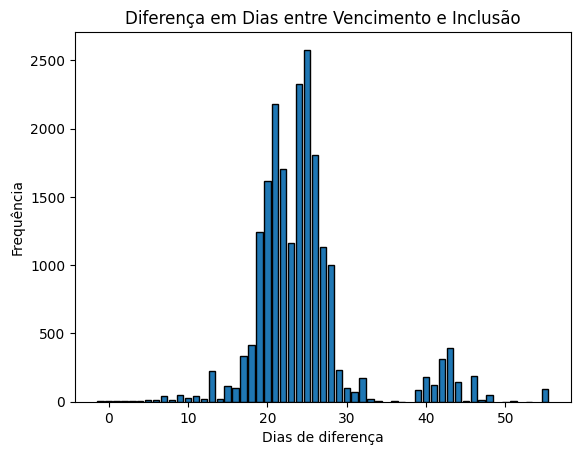

In [39]:


# Gráfico de barras
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Dias de diferença")
plt.ylabel("Frequência")
plt.show()


C:\Users\Inteli\AppData\Local\Temp\ipykernel_33268\1235095777.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  boletosPagos['vl_boleto'] = pd.to_numeric(boletosPagos['vl_boleto'], errors='coerce')


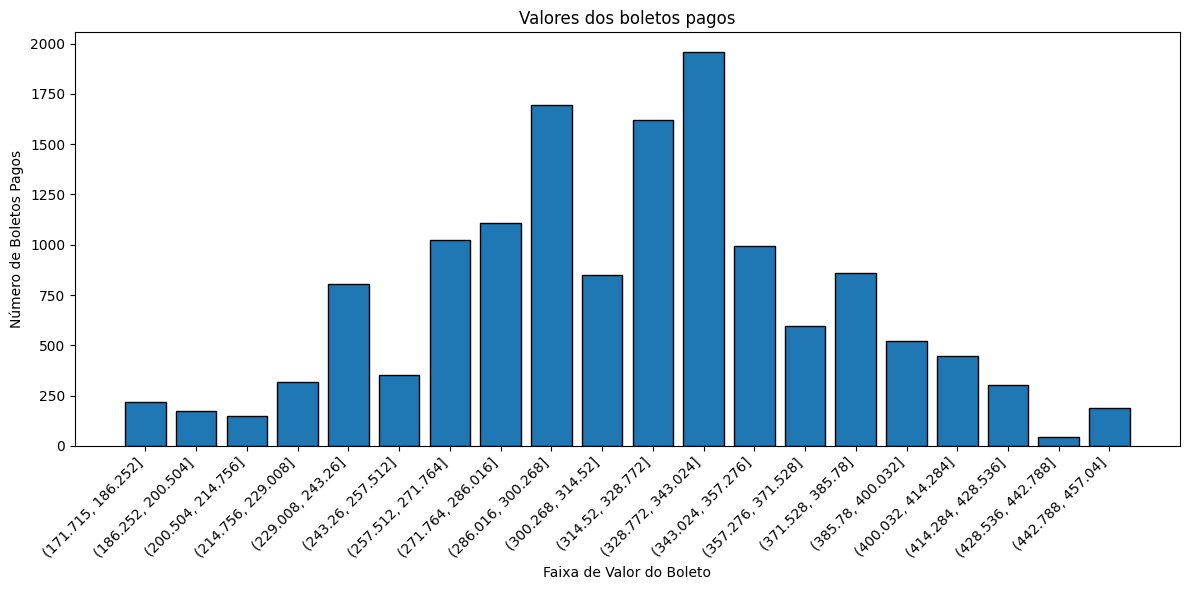

In [40]:
boletosPagos = TabelaAtual[TabelaAtual['status_num'] == 2]

boletosPagos['vl_boleto'] = pd.to_numeric(boletosPagos['vl_boleto'], errors='coerce')

# Remover linhas que ficaram NaN (eram inválidas)
boletosPagos = boletosPagos.dropna(subset=['vl_boleto'])

# Cria as faixas
bins = 20
boletosPagos['faixa_boleto'] = pd.cut(boletosPagos['vl_boleto'], bins=bins)

# Conta por faixa
vBoletoPagosGrouped = boletosPagos['faixa_boleto'].value_counts().sort_index()

# Gráfico
fig, ax = plt.subplots(figsize=(12,6))
ax.bar(vBoletoPagosGrouped.index.astype(str), vBoletoPagosGrouped.values, edgecolor="black")

ax.set_title("Valores dos boletos pagos")
ax.set_xlabel("Faixa de Valor do Boleto")
ax.set_ylabel("Número de Boletos Pagos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

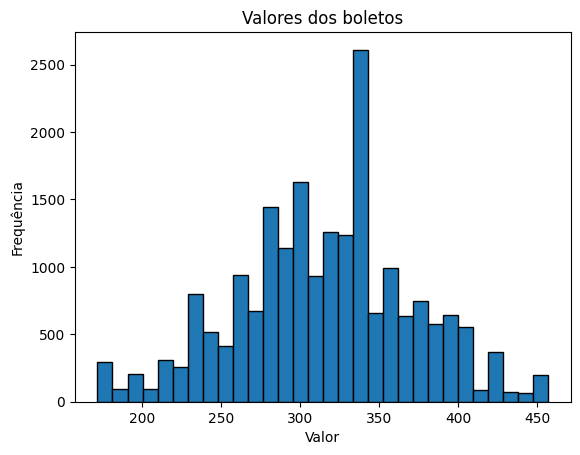

In [41]:
vBoleto = TabelaAtual['vl_boleto'].value_counts().sort_index()

plt.hist(TabelaAtual['vl_boleto'], bins=30, edgecolor="black")

plt.title("Valores dos boletos")
plt.xlabel("Valor")
plt.ylabel("Frequência")
plt.show()

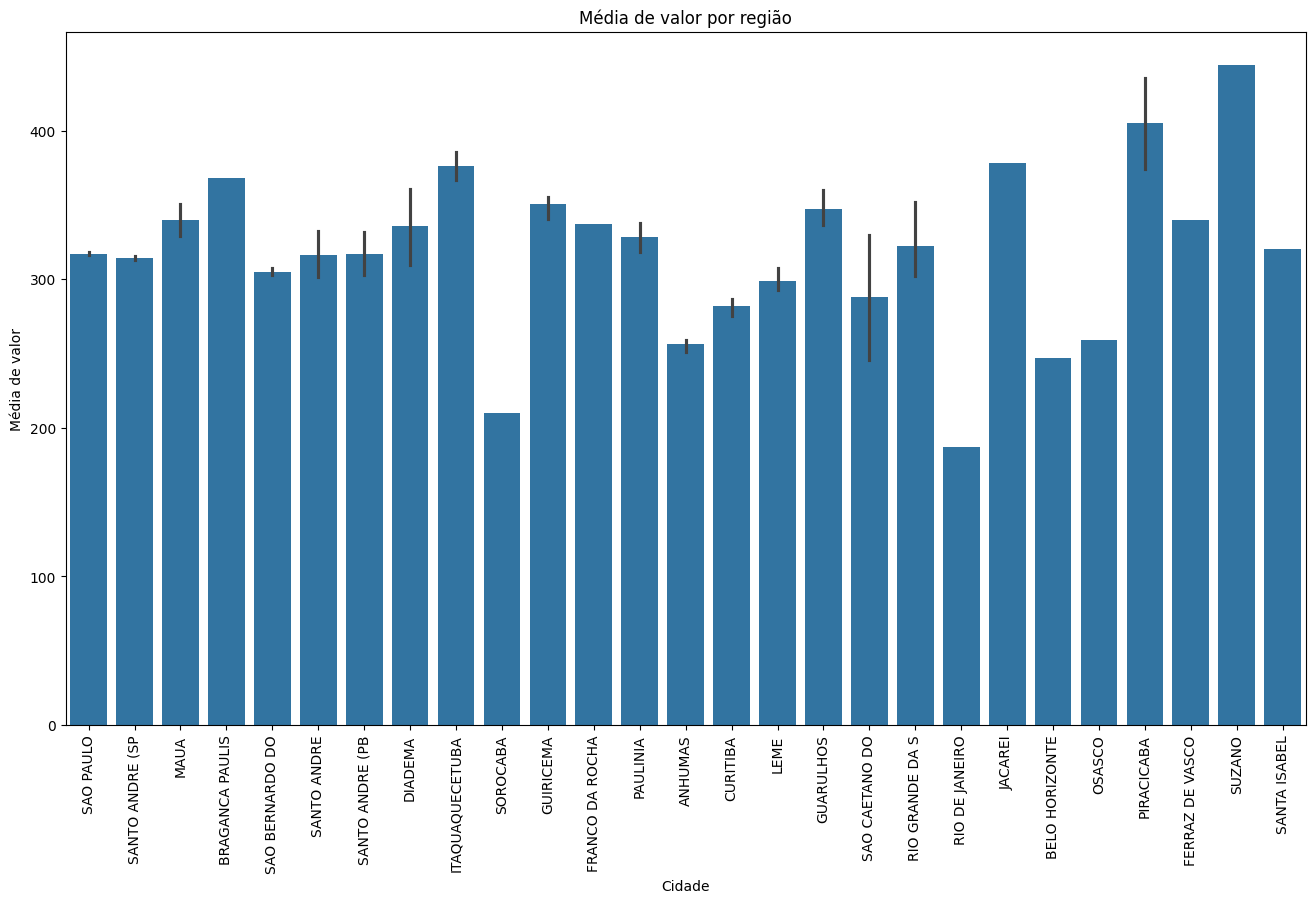

In [42]:


numeroPorCidade = TabelaAtual['pagador_cidade'].value_counts().sort_index()

plt.figure(figsize=(16,9))
sns.barplot(x="pagador_cidade", y="vl_boleto", data=TabelaAtual, estimator="mean")
plt.xticks(rotation=90)
plt.title("Média de valor por região")
plt.xlabel("Cidade")
plt.ylabel("Média de valor")
plt.show()

C:\Users\Inteli\AppData\Local\Temp\ipykernel_33268\1187532597.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
C:\Users\Inteli\AppData\Local\Temp\ipykernel_33268\1187532597.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()


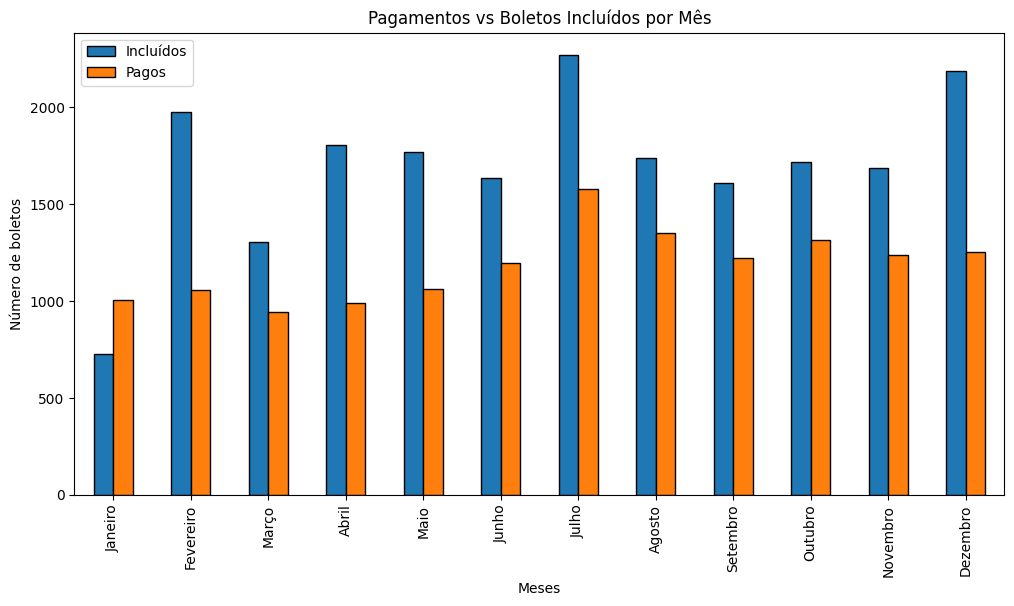

In [43]:
TabelaAtual['mes_pag'] = pd.Categorical(TabelaAtual['mes_pag'], categories=ordem_meses, ordered=True)
TabelaAtual['mes_inclusao'] = pd.Categorical(TabelaAtual['mes_inclusao'], categories=ordem_meses, ordered=True)
TabelaAtual['mes_vencimento'] = pd.Categorical(TabelaAtual['mes_vencimento'], categories=ordem_meses, ordered=True)
# Agrupamento
boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()

# Unir em dataframe
df_mes = pd.concat([boletos_incluidos, boletos_pagos], axis=1)
df_mes.columns = ['Incluídos', 'Pagos']
df_mes = df_mes.fillna(0)

# Taxa de pagamento
df_mes['Taxa'] = (df_mes['Pagos'] / df_mes['Incluídos']) * 100

# Gráfico
fig, ax1 = plt.subplots(figsize=(12, 6))

df_mes[['Incluídos', 'Pagos']].plot(kind='bar', ax=ax1, edgecolor="black")
ax1.set_ylabel("Número de boletos")
ax1.set_xlabel("Meses")
ax1.set_title("Pagamentos vs Boletos Incluídos por Mês")


# Legendas
ax1.legend(loc="upper left")


plt.show()

## 3.3 Hipóteses

 Nesta análise, foram levantadas hipóteses relacionadas ao comportamento de pagamento de boletos pelos usuários da plataforma. O objetivo é identificar padrões e fatores que influenciam o tempo de pagamento. Essas hipóteses servem como base para exploração de dados e para a criação do modelo preditivo, auxiliando na compreensão dos fatores que impactam atrasos, pontualidade nos pagamentos e permitem identificar quais variáveis impactão ou não no pagamento de boletos.

### 3.3.1 Hipótese 1 - Dias necessários para o pagamento de boletos

**Tese:** A maioria dos boletos, tanto pagos quanto não pagos, possui um intervalo entre a data de inclusão e a data de vencimento concentrado entre 20 e 30 dias.

**Resultado:** Positivo, ambos possuem um intervalo concentrado entre 20 e 30 dias.

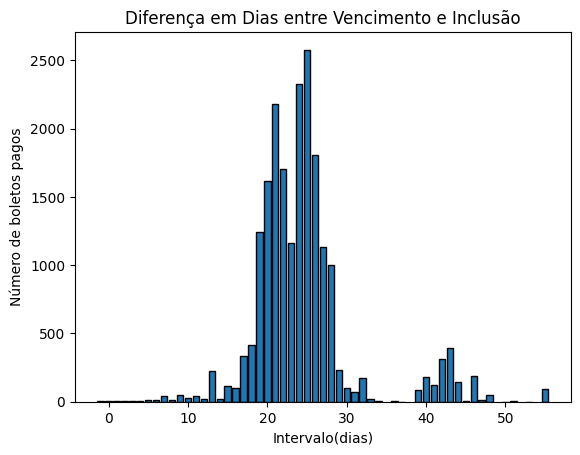

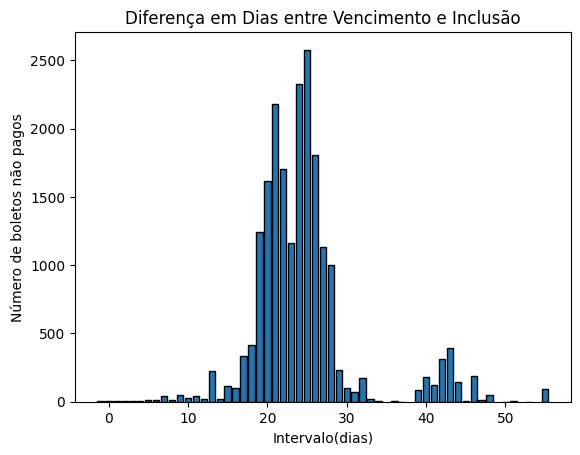

In [44]:


# Gráfico de barras - Boletos Pagos
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Intervalo(dias)")
plt.ylabel("Número de boletos pagos")
plt.show()

# Gráfico de barras - Boletos Não Pagos
plt.bar(TipoData.index, TipoData.values, edgecolor="black")
plt.title("Diferença em Dias entre Vencimento e Inclusão")
plt.xlabel("Intervalo(dias)")
plt.ylabel("Número de boletos não pagos")
plt.show()

### 3.3.2 Hipótese 2 -  O período do ano influencia diretamente na taxa de pagamento de boletos.

&nbsp;&nbsp;&nbsp;&nbsp; Esta hipótese busca confirmar que a taxa de pagamento de boletos varia de acordo com o mês ou período do ano, influenciada por fatores sazonais e econômicos. Em determinados meses, como dezembro (festividades de fim de ano) ou março/abril (pagamento de impostos), pode haver uma maior pressão financeira, reduzindo a taxa de quitação de boletos. Já em períodos de maior liquidez, como meses de recebimento de 13º salário ou distribuição de bônus corporativos, a taxa de pagamento tende a aumentar. Além disso, mudanças na governança ou estratégias financeiras das empresas ao longo do ano podem impactar diretamente a capacidade de honrar pagamentos.

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, análisamos mais de 30 mil boletos entre um período de 12 meses, utilizando Python e bibliotecas como Pandas, Matplotlib e Seaborn. O eixo X representa os meses do ano, enquanto o Y representa o número de boletos. A barra em azul representa os boletos incluídos, a laranja os boletos pagos e a linha vermelha representa a taxa de pagamento em porcentagem.


C:\Users\Inteli\AppData\Local\Temp\ipykernel_33268\3366486240.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
C:\Users\Inteli\AppData\Local\Temp\ipykernel_33268\3366486240.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()


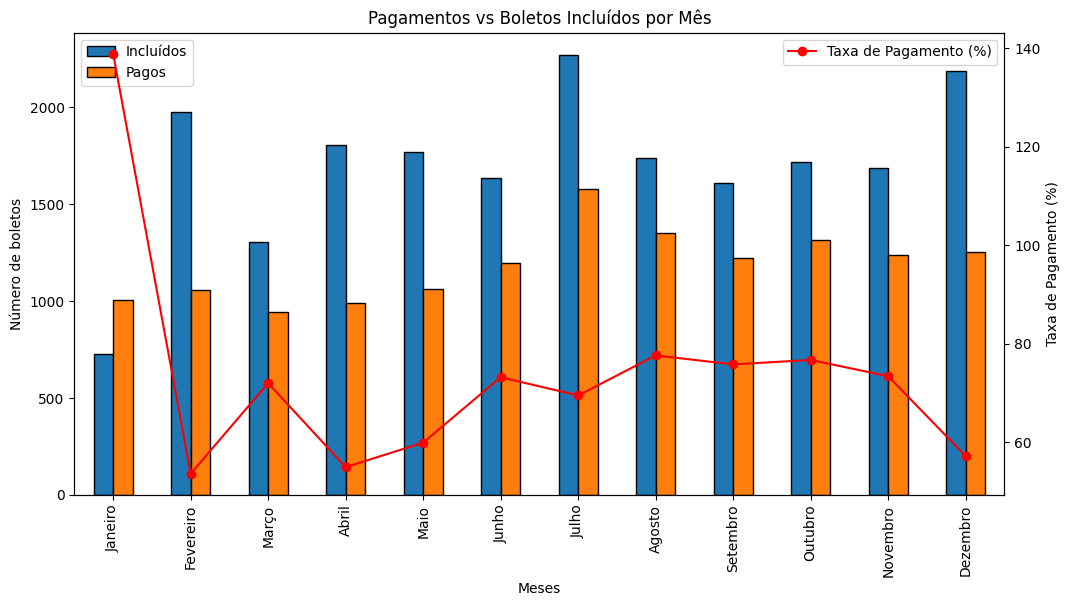

In [45]:


TabelaAtual['mes_pag'] = pd.Categorical(TabelaAtual['mes_pag'], categories=ordem_meses, ordered=True)
TabelaAtual['mes_inclusao'] = pd.Categorical(TabelaAtual['mes_inclusao'], categories=ordem_meses, ordered=True)
TabelaAtual['mes_vencimento'] = pd.Categorical(TabelaAtual['mes_vencimento'], categories=ordem_meses, ordered=True)

# Agrupamento
boletos_incluidos = TabelaAtual.groupby('mes_inclusao').size()
boletos_pagos = TabelaAtual[TabelaAtual['status_num'] == 2].groupby('mes_pag').size()

# Unir em dataframe
df_mes = pd.concat([boletos_incluidos, boletos_pagos], axis=1)
df_mes.columns = ['Incluídos', 'Pagos']
df_mes = df_mes.fillna(0)

# Taxa de pagamento
df_mes['Taxa'] = (df_mes['Pagos'] / df_mes['Incluídos']) * 100

# Gráfico
fig, ax1 = plt.subplots(figsize=(12, 6))

df_mes[['Incluídos', 'Pagos']].plot(kind='bar', ax=ax1, edgecolor="black")
ax1.set_ylabel("Número de boletos")
ax1.set_xlabel("Meses")
ax1.set_title("Pagamentos vs Boletos Incluídos por Mês")

# Eixo secundário
ax2 = ax1.twinx()
ax2.plot(df_mes.index, df_mes['Taxa'], color="red", marker="o", label="Taxa de Pagamento (%)")
ax2.set_ylabel("Taxa de Pagamento (%)")

# Legendas
ax1.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.show()

    

&nbsp;&nbsp;&nbsp;&nbsp; A análise do gráfico revela padrões importantes no comportamento de pagamento dos boletos. Em janeiro, observa-se que a quantidade de pagamentos supera a de inclusões, o que desmonstra o impacto das festividades e despesas concentradas no fim do ano. Isso ocorre porque em dezembro há um aumento expressivo na emissão de boletos, enquanto em janeiro, período de retomada das atividades, o número de novos boletos é significativamente menor.

&nbsp;&nbsp;&nbsp;&nbsp; Além disso, nota-se que em abril a taxa de pagamentos apresenta um dos menores índices do ano, o que pode estar associado à sobrecarga financeira causada pelo pagamento de impostos obrigatórios, como o Imposto de Renda e tributos anuais. Esse padrão reforça a influência de fatores econômicos e sazonais na dinâmica de pagamento.

**Resultado:** Portanto, é possível afirmar que o período do ano influncia diretamente no pagamento de boletos.

### 3.3.3 Hipótese 3 - O tempo necessário para pagamento de boletos varia de acordo com o perfil financeiro e comportamento dos clientes

&nbsp;&nbsp;&nbsp;&nbsp; Esta hipótese busca confirmar que o tempo necessário para pagamento de boletos varia de acordo com o perfil financeiro e comportamento dos clientes. Observa-se que grande parte dos boletos é quitada dentro dos primeiros 30 dias após a inclusão, indicando que muitos clientes priorizam pagamentos imediatos. Por outro lado, uma parcela menor apresenta atrasos mais longos, podendo estar relacionada a dificuldades financeiras temporárias, menor disciplina de pagamento ou atrasos na compensação bancária.

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, o eixo X representa os dias necessários para pagar, enquanto o eixo Y representa o número de boletos quitados em cada período. Cada ponto azul indica a quantidade de boletos pagos após determinado número de dias desde a inclusão.

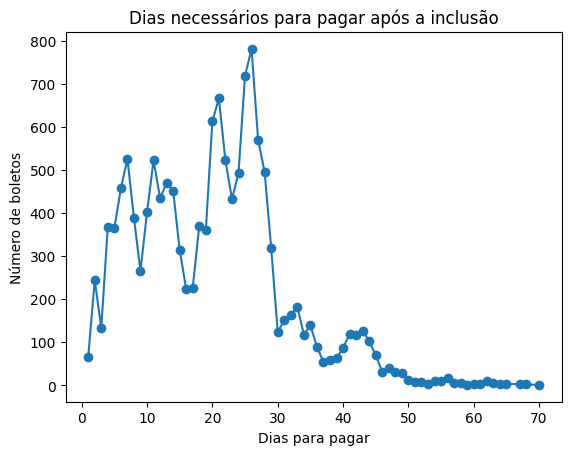

In [46]:

    # Gráfico de barras
plt.plot(DiasParaPagar.index, DiasParaPagar.values, marker="o")
plt.title("Dias necessários para pagar após a inclusão")
plt.xlabel("Dias para pagar")
plt.ylabel("Número de boletos")
plt.show()


&nbsp;&nbsp;&nbsp;&nbsp; A análise do gráfico revela padrões importantes no comportamento de pagamento. Observa-se um pico significativo entre 20 e 30 dias, sugerindo que a maioria dos clientes paga dentro do prazo mensal típico. Além disso, o número de boletos pagos decresce rapidamente após 40 dias, evidenciando que atrasos prolongados são menos frequentes, mas ainda presentes, indicando a necessidade de monitoramento e estratégias de cobrança para evitar inadimplência.

&nbsp;&nbsp;&nbsp;&nbsp; **Resultado:** Portanto, é possível afirmar que o tempo de pagamento de boletos segue um padrão concentrado nos primeiros 30 dias, com uma diminuição acentuada à medida que os dias avançam.

### 3.3.4 Hipótese 4 - Boletos com valores mais altos tendem a ser pagos em um maior número de dias após a emissão, enquanto boletos de menor valor costumam ser liquidados mais rapidamente.

&nbsp;&nbsp;&nbsp;&nbsp; Essa hipótese busca afirmar se valores elevados representam um maior impacto no orçamento do cliente, já que exigem maior planejamento financeiro, o que pode gerar atrasos ou maior tempo médio até o pagamento.

&nbsp;&nbsp;&nbsp;&nbsp; Esse comportamento pode estar associado tanto ao poder aquisitivo dos clientes quanto à priorização de despesas no ciclo financeiro. 

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, o eixo X representa os dias necessários para pagar o boleto e o Y o valor do boleto.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_33268\3912009524.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')


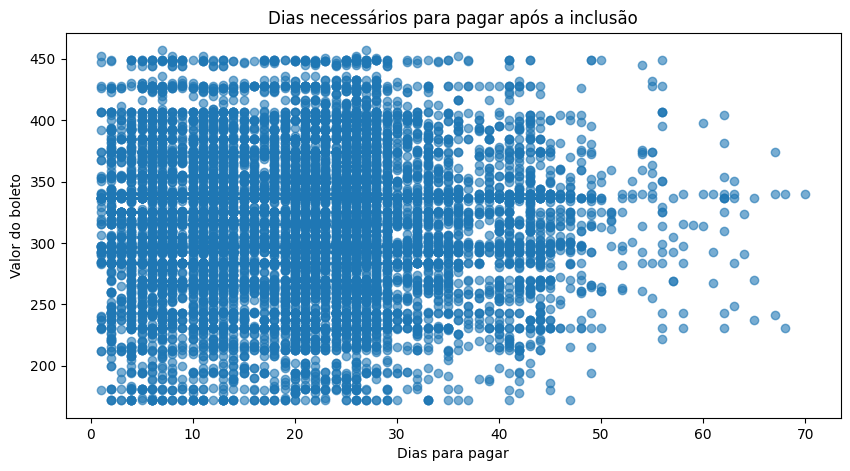

In [47]:
DiasParaPagar = TabelaAtual[TabelaAtual['dias_para_pagar'] > 0] 
DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
plt.figure(figsize=(10,5)) 
plt.scatter(DiasParaPagar['dias_para_pagar'], DiasParaPagar['vl_boleto'], alpha=0.6, marker="o") 
plt.title("Dias necessários para pagar após a inclusão") 
plt.xlabel("Dias para pagar") 
plt.ylabel("Valor do boleto") 
plt.show()

&nbsp;&nbsp;&nbsp;&nbsp; A partir da análise do gráfico acima, é possível identificar que não há uma tendência linear clara entre essas variáveis. A maioria dos pagamentos ocorre em até 30 dias, concentrando-se em boletos de R$ 200 a R$ 400. Casos isolados de valores acima de R$ 450 mostram pagamentos tanto rápidos quanto atrasados, sugerindo que o valor sozinho não determina o tempo de quitação. Após 40 dias, os pagamentos se tornam mais raros. Assim, o prazo para pagamento parece depender mais de fatores como comportamento do cliente, sazonalidade ou disciplina financeira, indicando que o valor do boleto deve ser analisado junto a outras variáveis em modelos preditivos.

**Resultado:** Portanto, é possível afirmar que NÃO há uma relação clara entre o valor do boleto e tempo necessário para pagar.


### 3.3.5 Hipótese 5 - A média de acesso de pessoas que pagaram o boleto é maior que as que não pagaram.

&nbsp;&nbsp;&nbsp;&nbsp; Essa hipótese busca confirmar que usuários que efetivam o pagamento de seus boletos tendem a apresentar uma quantidade de acessos à plataforma significativamente maior do que aqueles que não realizam o pagamento.

&nbsp;&nbsp;&nbsp;&nbsp; O número de acessos pode refletir o nível de engajamento do usuário com a plataforma. Um usuário mais engajado costuma ter maior contato com os serviços, maior percepção de valor e, consequentemente, maior probabilidade de honrar o pagamento. Por outro lado, usuários com baixa frequência de acessos podem demonstrar desinteresse ou menor vínculo, aumentando a chance de inadimplência.

&nbsp;&nbsp;&nbsp;&nbsp; Se a hipótese for confirmada, a quantidade de acesso pode se tornar uma forte variável na implementação do modelo preditivo, pois se torna um dos indicadores de pagamento e influencia na busca de inadimplentes.

&nbsp;&nbsp;&nbsp;&nbsp; No gráfico abaixo, o eixo X possui dois valores, os boletos pagos e não pagos, enquanto o eixo Y representa a média de acessos dos usuários de cada um desses grupos.

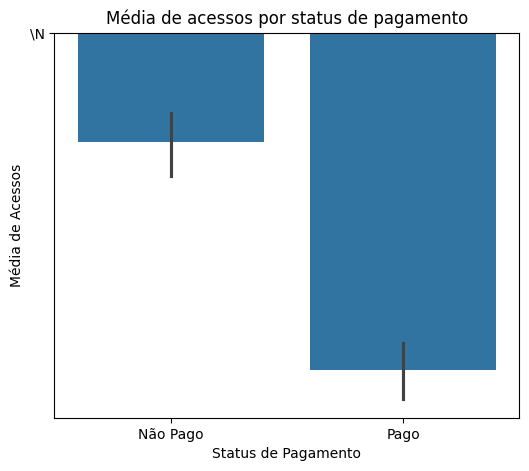

In [48]:
plt.figure(figsize=(6,5))
sns.barplot(x="pago/n", y="qtd_acessos_pagador", data=TabelaAtual, estimator="mean")

plt.title("Média de acessos por status de pagamento")
plt.xlabel("Status de Pagamento")
plt.ylabel("Média de Acessos")
plt.show()


**Resultado:** Portanto, através da análise do gráfico, é possível confirmar que a média de acessos das pessoas que pagaram os boletos é consideravelmente maior que das pessoas que não pagaram.

### 3.3.6. Hipótese 6 - Média de valor entre boletos pagos e não pagos

&nbsp;&nbsp;&nbsp;&nbsp; Esta hipótese busca afirmar que a média de valor é maior para os boletos com status 'Não Pago', sugerindo que valores mais altos podem influenciar negativamente a quitação dos boletos.

C:\Users\Inteli\AppData\Local\Temp\ipykernel_33268\3570382528.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')


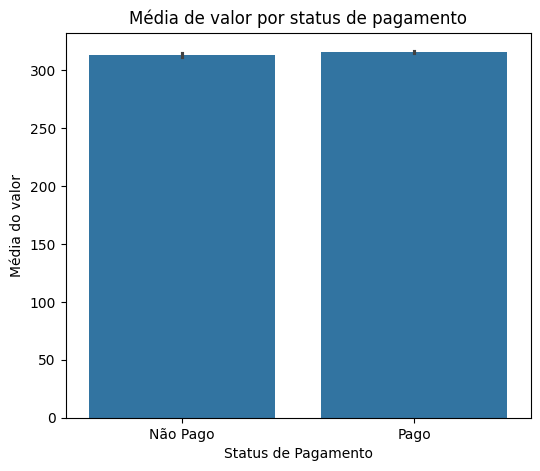

In [49]:

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
TabelaAtual['pago/n'] = TabelaAtual['status_num'].map(mapping)

TabelaAtual['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
DiasParaPagar['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
plt.figure(figsize=(6,5))
sns.barplot(x="pago/n", y="vl_boleto", data=TabelaAtual, estimator="mean")

plt.title("Média de valor por status de pagamento")
plt.xlabel("Status de Pagamento")
plt.ylabel("Média do valor")
plt.show()

**Resultado**: Após a análise do gráfico, pode-se concluir que a média de valor entre boletos pagos e não pagos é praticamente igual, o que anula completamente a hipótese de que a média de valor de boletos não pagos é maior.


&nbsp;&nbsp;&nbsp;&nbsp; As hipóteses levantadas permitem direcionar análises quantitativas para verificar a influência de diferentes fatores sobre o comportamento de pagamento. A avaliação de padrões relacionados a valores, frequência de acessos e histórico de pagamentos ajuda a confirmar ou rejeitar essas hipóteses, identificando as variáveis relevantes para a criação do nosso modelo preditivo destinado a Finnet.


## 4. Criação do Modelo Preditivo

&nbsp;&nbsp;&nbsp;&nbsp; Nessa seção, foram desenvolvidos os modelos preditivos necessários para atender às entregas propostas no TAPI, cada um deles com objetivos específicos:


- Modelo de tendência de pagamento: estruturado como um problema de classificação e de aprendizado supervisionado, esse modelo prevê se o pagamento ocorrerá em dia, com atraso ou se resultará em inadimplência, fornecendo uma visão antecipada do comportamento do pagador.

- Modelo da melhor janela de pagamento provável: desenvolvido para identificar o período mais adequado em que o pagador tende a realizar o pagamento, oferecendo subsídios para ações proativas de cobrança e definição de prazos estratégicos. Esse modelo será estruturado como um problema de regressão e a aprendizagem será feita de forma supervisionada.

- Modelo de impacto projetado no fluxo de recebimentos: criado para estimar como diferentes cenários de pagamento (adimplência, atraso ou inadimplência) afetam o fluxo de caixa futuro, permitindo ao grupo avaliar riscos financeiros e tomar decisões de planejamento. Esse modelo será estruturado como um problema de regressão e a aprendizagem será feita de forma supervisionada.

### 4.1 Tratamento dos dados

&nbsp;&nbsp;&nbsp;&nbsp; Durante o processo de criação de gráficos e hipóteses, alguns dos novos dados criados durante esse processo não foram previamente tratados e normalizados, dessa forma, realizamos novamente a substituição dos valores nulos, codificação das variáveis categóricas e substituição dos valores ausentes.

### 4.1.1 Substituindo valores nulos

&nbsp;&nbsp;&nbsp;&nbsp; O código abaixo, substitui os valores ausentes preenchidos por NaN (Not a Number) das tabelas **dias_para_pagar**, **qtd_acessos_pagador_norm** e **pago/n** por 0, assim possibilitando a utilização dessas dados pelo modelo preditivo.

In [50]:
TabelaAtual = TabelaGeral

TabelaAtual['banco'] = TabelaAtual['banco'].astype(str)
TabelaAtual['tipo_juros'] = TabelaAtual['tipo_juros'].astype(str)
TabelaAtual['tipo_multa'] = TabelaAtual['tipo_multa'].astype(str)

Banco_encoder = LabelEncoder()
Cidade_Pagador_encoder = LabelEncoder()
Status_boleto_encoder = LabelEncoder()
Juros_encoder = LabelEncoder()
cep_encoder = LabelEncoder()
Multa_encoder = LabelEncoder()
Tipo_pagador_encoder = LabelEncoder()

Banco_encoder.fit(TabelaAtual['banco'])
TabelaAtual['banco'] = Banco_encoder.fit_transform(TabelaAtual['banco'])

Tipo_pagador_encoder.fit(df_proc['pagador_cnpjcpf'])
df_proc['pagador_cnpjcpf'] = Tipo_pagador_encoder.fit_transform(df_proc['pagador_cnpjcpf'])

Cidade_Pagador_encoder.fit(TabelaAtual['pagador_cidade'])
TabelaAtual['pagador_cidade'] = Cidade_Pagador_encoder.transform(TabelaAtual['pagador_cidade'])

Status_boleto_encoder.fit(TabelaAtual['status_boleto'])
TabelaAtual['status_boleto'] = Status_boleto_encoder.transform(TabelaAtual['status_boleto'])

Juros_encoder.fit(TabelaAtual['tipo_juros'])
TabelaAtual['tipo_juros'] = Juros_encoder.transform(TabelaAtual['tipo_juros'])

Multa_encoder.fit(TabelaAtual['tipo_multa'])
TabelaAtual['tipo_multa'] = Multa_encoder.transform(TabelaAtual['tipo_multa'])

TabelaAtual['pagador_cep'] = TabelaAtual['pagador_cep'].fillna('0').astype(str)
cep_encoder.fit(TabelaAtual['pagador_cep'])
TabelaAtual['pagador_cep'] = cep_encoder.transform(TabelaAtual['pagador_cep'])


TabelaAtual['pagador_cidade'] = Cidade_Pagador_encoder.inverse_transform(TabelaAtual['pagador_cidade'])
TabelaAtual['status_boleto'] = Status_boleto_encoder.inverse_transform(TabelaAtual['status_boleto'])

# Convertendo Datas em string para DATETIME

TabelaAtual['data_vencto'] = pd.to_datetime(TabelaAtual['data_vencto'], errors='coerce', dayfirst=True)
TabelaAtual['data_inclusao'] = pd.to_datetime(TabelaAtual['data_inclusao'], errors='coerce', dayfirst=True)
TabelaAtual['dt_pagto'] = pd.to_datetime(TabelaAtual['dt_pagto'], errors='coerce', dayfirst=True)

# Convertendo de INT para numérico

TabelaAtual['vl_boleto'] = pd.to_numeric(TabelaAtual['vl_boleto'], errors='coerce')
TabelaAtual['juros'] = pd.to_numeric(TabelaAtual['juros'], errors='coerce')

# Criando coluna em númérico do status do boleto
print(TabelaAtual['status_boleto'])
mapping = {'REGISTRADO': 0, 'BAIXADO': 1, 'LIQUIDADO': 2}
TabelaAtual['status_num'] = TabelaAtual['status_boleto'].map(mapping)



# Dicionário de mapeamento mês
mapping = {
    1: 'Janeiro', 2: 'Fevereiro', 3: 'Março', 4: 'Abril',
    5: 'Maio', 6: 'Junho', 7: 'Julho', 8: 'Agosto',
    9: 'Setembro', 10: 'Outubro', 11: 'Novembro', 12: 'Dezembro'
}


# Criar colunas de mês
TabelaAtual['mes_pag'] = TabelaAtual['dt_pagto'].dt.month.map(mapping)
TabelaAtual['mes_inclusao'] = TabelaAtual['data_inclusao'].dt.month.map(mapping)
TabelaAtual['mes_vencimento'] = TabelaAtual['data_vencto'].dt.month.map(mapping)
ordem_meses = list(mapping.values())

TabelaAtual['dia_vencimento'] = TabelaAtual['data_vencto'].dt.day
print(TabelaAtual['dia_vencimento'])
ordem_meses = list(mapping.values())
# Filtrando boletos pagos
boletosPagos = TabelaAtual[(TabelaAtual['status_num'] == 2)]

DiasParaPagar = (boletosPagos['dt_pagto'] - boletosPagos['data_inclusao']).dt.days
TabelaAtual['dias_para_pagar'] = DiasParaPagar
DiasParaVencer = (TabelaAtual['data_vencto'] - TabelaAtual['data_inclusao']).dt.days
TabelaAtual['dias_para_vencer'] = DiasParaVencer
DiasParaPagar = DiasParaPagar.value_counts().sort_index()


dataVen = TabelaAtual['data_vencto']
dataInc = TabelaAtual['data_inclusao']
Datas = (dataVen - dataInc).dt.days

TipoData = Datas.value_counts()
TipoData = TipoData.sort_index()

mapping = {0: 'Não Pago', 1: 'Não Pago', 2: 'Pago'}
TabelaAtual['pago/n'] = TabelaAtual['status_num'].map(mapping)
TabelaAtual['dias_para_pagar'] = TabelaAtual['dias_para_pagar'].replace(np.nan, 0)
TabelaAtual['qtd_acessos_pagador_norm'] = TabelaAtual['qtd_acessos_pagador_norm'].replace(np.nan, 0)
TabelaAtual['qtd_acessos_pagador'] = TabelaAtual['qtd_acessos_pagador'].replace(np.nan, 0)
TabelaAtual['pago/n'] = TabelaAtual['pago/n'].fillna(0)
TabelaAtual['pago/n'] = TabelaAtual['pago/n'].replace('\\N', 0)

0          REGISTRADO
1          REGISTRADO
2          REGISTRADO
3          REGISTRADO
4          REGISTRADO
              ...    
1635424     LIQUIDADO
1635425    REGISTRADO
1635426    REGISTRADO
1635427    REGISTRADO
1635428     LIQUIDADO
Name: status_boleto, Length: 1635429, dtype: object
0          30.0
1          23.0
2          24.0
3          29.0
4          28.0
           ... 
1635424    11.0
1635425    25.0
1635426     9.0
1635427    24.0
1635428    24.0
Name: dia_vencimento, Length: 1635429, dtype: float64


### 4.1.2 Transformando novas features em Label Encoder

&nbsp;&nbsp;&nbsp;&nbsp; Após a criação de novas features durante o processo de criação dos gráficos, foi necessário transformar as novas features desenvolvidas nos gráficos, hipóteses e na preparação do modelo preditivo, para o formato Label Encoder, tramsformando assim variáveis categóricas como (**mes_inclusão**, **mes_pag**, **pagador_inscricao_hash**, **pago/n (pago ou não)** e **mes_vencto**) em números que representam cada uma das categorias, para que assim, os dados possam ser entendidos pelo modelo.

In [51]:

mesEncoder = LabelEncoder()
mesEncoder.fit(TabelaAtual['mes_inclusao'])
TabelaAtual['mes_inclusao'] = mesEncoder.fit_transform(TabelaAtual['mes_inclusao'])

mesEncoder.fit(TabelaAtual['mes_pag'])
TabelaAtual['mes_pag'] = mesEncoder.fit_transform(TabelaAtual['mes_pag'])

pagadorHash = LabelEncoder()
pagadorHash.fit(TabelaAtual['pagador_inscricao_hash'])
TabelaAtual['pagador_inscricao_hash'] = pagadorHash.fit_transform(TabelaAtual['pagador_inscricao_hash'])

TabelaAtual['pago/n'] = TabelaAtual['pago/n'].astype(str)
pagoEncoder = LabelEncoder()
pagoEncoder.fit(TabelaAtual['pago/n'])
TabelaAtual['pago/n'] = pagoEncoder.transform(TabelaAtual['pago/n'])

mesVencto = LabelEncoder()
mesVencto.fit(TabelaAtual['mes_vencimento'])
TabelaAtual['mes_vencimento'] = mesVencto.fit_transform(TabelaAtual['mes_vencimento'])



### 4.1.3 Normalizando os dados

&nbsp;&nbsp;&nbsp;&nbsp; Durante a criação do modelo preditivo, notamos que a alta dispersão de valores dos dados interfere diretamente na acurácia e resultados do modelo. Portanto, se fez necessário criar uma escala padrão para as colunas, assim transformando as linhas de algumas colunas em números em uma escala de (0,1) para melhor aproximação dos dados e assim garantindo melhores resultados e acurácia nos modelos criados. 

In [52]:
# Colunas categóricas que ainda são strings
categoricas = ['pagador_cnpjcpf', 'pago/n', 'banco', 'tipo_juros', 'tipo_multa']

for col in categoricas:
    # Preencher nulos e converter para string
    TabelaAtual[col] = TabelaAtual[col].fillna('NA').astype(str)
    # Label encoding
    le = LabelEncoder()
    TabelaAtual[col] = le.fit_transform(TabelaAtual[col])

# Agora MinMaxScaler só nas colunas numéricas
numericas = ['pagador_inscricao_hash', 'mes_pag', 'mes_inclusao', 'dias_para_pagar',
             'dias_para_vencer', 'pago/n', 'banco', 'dia_vencimento', 'mes_vencimento', 'pagador_cnpjcpf']

scaler = MinMaxScaler(feature_range=(0, 1))
for col in numericas:
    TabelaAtual[col + '_norm'] = scaler.fit_transform(TabelaAtual[[col]])


## 4.2 Modelo Preditivo de Tendência de Pagamentos

&nbsp;&nbsp;&nbsp;&nbsp; O modelo preditivo de tendência de pagamentos tem como objetivo identificar a probabilidade de o devedor realizar o próximo pagamento em dia, com atraso ou em inadimplência. Trata-se de um problema de aprendizado supervisionado, classificado como classificação multiclasse. Para viabilizar o treinamento, foi criada a variável alvo denominada “Status de Pagamento”, utilizada como variável Y no processo de modelagem preditiva.

### 4.2.1 Features

&nbsp;&nbsp;&nbsp;&nbsp; As features correspondem às variáveis explicativas utilizadas pelo modelo preditivo, ou seja, são os atributos extraídos das colunas dos boletos que fornecem informações relevantes para estimar a tendência de pagamento do usuário. Cada feature representa um aspecto do comportamento do pagador ou das características dos boletos.

#### 4.2.1.1 Variável Alvo Y (Status do Pagamento)

&nbsp;&nbsp;&nbsp;&nbsp; No desenvolvimento do modelo de tendência de pagamento, fez se necessário estabelecer, para cada boleto, qual foi o resultado do pagamento: em dia, em atraso ou inadimplente. Essa informação é representada pela variável alvo (y), que corresponde ao valor que o modelo deve aprender a prever.

&nbsp;&nbsp;&nbsp;&nbsp; Em outras palavras, enquanto as features (variáveis independentes) fornecem as características descritivas dos boletos e dos pagadores, a variável alvo indica o comportamento final que se deseja estimar. No caso em questão, a variável alvo foi definida como “Status de Pagamento”, classificando cada boleto em uma das três categorias mencionadas. Essa categorização serve de referência durante o treinamento, permitindo que o algoritmo aprenda padrões e consiga, posteriormente, prever a tendência de pagamento de novos boletos.

&nbsp;&nbsp;&nbsp;&nbsp; No código abaixo foi utilizada a data de vencimento e de pagamento para calcular o número de dias que cada boleto levou para ser pago. Se o número de dias for qualquer número positivo maior que 0, significa que o boleto foi pago em dia, se for entre -1 e -30, significa que o boleto foi pago com atraso e se tiver um valor menor que -30 (Ou seja, demorou mais de 30 dias para pagar) o boleto é considerado como inadimplente.

In [90]:
diasNecessáriosParaPagar = (TabelaAtual['data_vencto'] - TabelaAtual['dt_pagto']).dt.days

TabelaAtual['status_do_pagamento'] = None
# Definir status do pagamento
TabelaAtual.loc[diasNecessáriosParaPagar >= 0, 'status_do_pagamento'] = 'em dia'
TabelaAtual.loc[(diasNecessáriosParaPagar <= -1) & (diasNecessáriosParaPagar >= -30), 'status_do_pagamento'] = 'atrasado'
TabelaAtual.loc[diasNecessáriosParaPagar <= -31, 'status_do_pagamento'] = 'inadimplente'
print(TabelaAtual['status_do_pagamento'].value_counts())

TabelaAtual.loc[diasNecessáriosParaPagar >= 0, 'score_boleto'] = 1
TabelaAtual.loc[(diasNecessáriosParaPagar <= -1) & (diasNecessáriosParaPagar >= -30), 'score_boleto'] =  ((diasNecessáriosParaPagar) / 31) + 1 
TabelaAtual.loc[diasNecessáriosParaPagar <= -31, 'score_boleto'] = 0

# Remover coluna antiga se existir
if 'score_boleto_media' in TabelaAtual.columns:
    TabelaAtual = TabelaAtual.drop(columns=['score_boleto_media'])

# Preencher valores ausentes
TabelaAtual['status_do_pagamento'] = TabelaAtual['status_do_pagamento'].fillna('inadimplente')

# Calcular média por pagador_inscricao_hash
feature_pagador = TabelaAtual.groupby("pagador_inscricao_hash")["score_boleto"].mean()

# Criar coluna de score médio usando map (sem merge)
TabelaAtual['score_boleto_media'] = TabelaAtual['pagador_inscricao_hash'].map(feature_pagador)
# Verificar resultado
print(TabelaAtual['score_boleto_media'].value_counts())


TabelaAtual['score_boleto_media'] = TabelaAtual['score_boleto_media'].fillna(1)



status_do_pagamento
atrasado        707352
em dia          290822
inadimplente      5470
Name: count, dtype: int64
score_boleto_media
1.000000    111862
0.967742     47996
0.935484     26206
0.951613     16550
0.983871     16411
             ...  
0.604839         4
0.129032         4
0.182796         3
0.806452         3
0.354839         3
Name: count, Length: 5547, dtype: int64


#### 4.2.1.2 Variável X

&nbsp;&nbsp;&nbsp;&nbsp; O X representa o conjunto de variáveis independentes, também chamadas de features, que reúnem todas as informações utilizadas pelo modelo para aprender e prever a tendência de pagamento. No caso dos boletos, essas variáveis correspondem às colunas que descrevem características do boleto e do comportamento do pagador. Em resumo, o X é a entrada do modelo, formada por todos os atributos relevantes que permitem identificar padrões e antecipar se o pagamento ocorrerá em dia, com atraso ou inadimplente.

&nbsp;&nbsp;&nbsp;&nbsp; As features utilizadas no modelo de tendência de pagamentos foram:

- **Valor de boleto normalizado:** O valor do boleto é uma variável essencial para a predição do modelo preditivo, já que comprovamos através dos gráficos, que o valor do boleto tem impacto direto no pagamento do mesmo.
- **Quantidade de acessos:** A quantidade de acessos por pagador no boleto em específico é decisivo na predição de pagamento de boletos, já que através das hipóteses, foi comprovado que a média de acessos para os pagadores é muito maior do que aqueles que não pagam. Além disso, se a quantidade de acessos for igual a 0, há uma alta chance do boleto não ser pago, a menos que esteja em débito automático.
- **Número de inscrição do pagador em hash:** A inscrição do jogador em hash ajuda a separar dados de acordo com um pagador.
- **Juros:** O valor de juros de um boleto ajuda a identificar se o boleto será pago ou não, já que com um alto valor de juros, há uma alta chance do boleto não ser pago, enquanto um valor de juros igual a 0 representa que o boleto ainda não foi atrasado.
- **Mes_Vencimento:** Através da hipótese 2, foi comprovado que o mês de vencimento impacta diretamente no pagamento de boletos, uma vez que há meses como Janeiro, que uma alta taxa de boletos são pagos, enquanto outros como Abril (período de pagamento de impostos) que a taxa é baixíssima. Dessa forma, esse dado se torna essencial na criação de um modelo de predição de tendência de pagamento.
- **Dia de vencimento normalizado:** O dia de vencimento é uma variável importante para o modelo, pois o comportamento de pagamento pode variar de acordo com o dia do mês em que o boleto vence. Dias próximos ao início do mês, por exemplo, tendem a apresentar maior taxa de pagamento devido à entrada de salários, enquanto dias próximos ao fim do mês podem ter menor prioridade no pagamento.
- **CNPJ/CPF do pagador normalizado:** O identificador do pagador, representado em formato hash e normalizado, é essencial para distinguir diferentes perfis de clientes e capturar padrões de comportamento individualizados. Essa variável possibilita ao modelo associar o histórico de pagamentos de cada pagador à sua tendência futura, ajudando a identificar se determinados perfis estão mais propensos a pagar em dia, atrasar ou se tornar inadimplentes.

&nbsp;&nbsp;&nbsp;&nbsp; Outras features testadas no modelo preditivo, mas que não foram utilizadas na entrega:

- **Pago ou não:** a coluna **pago/n** que diz se o boleto foi pago ou não. Não foi utilizada pois causa leakage(vazamento de dados) no modelo.
- **Dias para pagar:** a coluna **dias_para_pagar** que conta o número de dias entre a data de inclusão e de pagamento. Não foi utilizada pois causa leakage(vazamento de dados) no modelo.
- **Valor de pagamento:** A coluna **vl_pagto_norm** mostra o valor de pagamento do boleto. Essa feature não foi utilizada pois além de causar leakage(vazamento de dados), não pode ser identificada antes do pagamento, portanto, para um modelo que prevê o pagamento, não há sentido em utilizá-la.


&nbsp;&nbsp;&nbsp;&nbsp; A escolha adequada das features é fundamental para a qualidade do modelo, pois são elas que fornecem os padrões que permitem ao algoritmo aprender e realizar previsões mais assertivas. Dessa forma, a etapa de definição e preparação das features garante que o modelo consiga captar as relações entre os boletos históricos e o status de pagamento futuro, servindo como base para a identificação de pagamentos em dia, com atraso ou inadimplentes.

### 4.2.2 Dividindo os dados entre X e y

&nbsp;&nbsp;&nbsp;&nbsp; O código abaixo seleciona algumas colunas do DataFrame TabelaAtual para formar as features (X) que serão usadas para treinar o modelo, e define a coluna status_do_pagamento como o alvo (y) que se quer prever. Em seguida, ele divide os dados em conjunto de treino (80%) e conjunto de teste (20%), mantendo a proporção das classes de status_do_pagamento igual em ambos os conjuntos, usando o parâmetro stratify.

In [87]:
X = TabelaAtual[['vl_boleto_norm', 
                 'qtd_acessos_pagador_norm', 
                 'pagador_inscricao_hash', 
                 'juros_norm',
                 'mes_vencimento_norm',
                 'dia_vencimento_norm',
                 'pagador_cnpjcpf_norm'
                 ]]

y = TabelaAtual['status_do_pagamento']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 4.2.3 Padronização e balanceamento dos dados

&nbsp;&nbsp;&nbsp;&nbsp; O código normaliza novamente os dados de treino e teste usando StandardScaler, centralizando em zero e ajustando a escala; depois, aplica o SMOTE no conjunto de treino para criar mais exemplos das classes minoritárias, equilibrando as classes de y_train antes de treinar o modelo.

In [88]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

### 4.2.4 Criando o modelo preditivo

&nbsp;&nbsp;&nbsp;&nbsp; Esse código faz uma busca em grade (Grid Search) para encontrar os melhores hiperparâmetros de uma árvore de decisão. Ele testa várias combinações de profundidade máxima, tamanho mínimo de divisão, tamanho mínimo de folha e critério de divisão, usando validação cruzada de 5 folds e avaliando pelo F1 macro. Depois de encontrar a melhor árvore, treina-a nos dados de treino balanceados pelo SMOTE e faz previsões no conjunto de teste.

In [90]:
param_grid = {
    'max_depth': [ 7, 10, None],
    'min_samples_split': [ 10, 20],
    'min_samples_leaf': [ 5, 10],
    'criterion': ['gini', 'entropy']
}

grid = RandomizedSearchCV(
    DecisionTreeClassifier(random_state=42, class_weight='balanced'),
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=4
)

grid.fit(X_train_res, y_train_res)
best_tree = grid.best_estimator_
y_pred = best_tree.predict(X_test_scaled)

PicklingError: Could not pickle the task to send it to the workers.

### 4.2.5 Métricas

&nbsp;&nbsp;&nbsp;&nbsp; O código abaixo avalia o desempenho do modelo de classificação usando várias métricas. Primeiro, calcula métricas gerais: acurácia, que indica a proporção de previsões corretas; precisão, que mostra a proporção de acertos entre todas as previsões feitas para cada classe (em dia, atraso ou inadimplente); recall, que mede a proporção de exemplos reais de cada classe que o modelo conseguiu identificar; e F1-Score, que é a média harmônica entre precisão e recall, ponderada pelo tamanho das classes, equilibrando falsos positivos e falsos negativos.

&nbsp;&nbsp;&nbsp;&nbsp; Em seguida, o código normaliza os rótulos (y_test e y_pred) para garantir que espaços extras ou diferenças de tipo não causem erros. Depois, gera um relatório detalhado por classe usando classification_report, mostrando precisão, recall, F1-Score e suporte (quantidade de exemplos reais) para cada categoria de pagamento.

&nbsp;&nbsp;&nbsp;&nbsp; Por fim, utiliza precision_recall_fscore_support para criar um DataFrame organizado com essas métricas por classe, facilitando a visualização, análise ou exportação dos resultados. Isso permite entender tanto o desempenho geral quanto como o modelo se comporta para cada classe individualmente, identificando possíveis falhas em classes minoritárias.

In [ ]:
# --- 1) Métricas gerais
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted")
rec = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Métricas do melhor modelo Decision Tree (geral):")
print(f"Acurácia: {acc:.4f}")
print(f"Precisão: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")


y_test = pd.Series(y_test).astype(str).str.strip()
y_pred = pd.Series(y_pred).astype(str).str.strip()


classes = ["inadimplente", "em dia", "atrasado"]
print(classification_report(y_test, y_pred, labels=classes, target_names=classes, zero_division=0))


precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=classes, zero_division=0
)

metrics_df = pd.DataFrame({
    "Classe": classes,
    "Precisão": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

print(metrics_df)

Métricas do melhor modelo Decision Tree (geral):
Acurácia: 0.5559
Precisão: 0.5656
Recall: 0.5559
F1-Score: 0.5586
              precision    recall  f1-score   support

inadimplente       0.55      0.52      0.53      1244
      em dia       0.65      0.58      0.61      1724
    atrasado       0.46      0.55      0.50      1119

    accuracy                           0.56      4087
   macro avg       0.55      0.55      0.55      4087
weighted avg       0.57      0.56      0.56      4087

         Classe  Precisão    Recall  F1-Score  Support
0  inadimplente  0.546678  0.522508  0.534320     1244
1        em dia  0.649157  0.580626  0.612982     1724
2      atrasado  0.457965  0.554960  0.501818     1119


### 4.2.6 Gráficos

&nbsp;&nbsp;&nbsp;&nbsp; Esses gráficos permitem visualizar de forma clara o desempenho do modelo. O primeiro é um gráfico de barras que mostra a precisão, o recall e o F1-Score para cada classe do modelo (inadimplente, em dia e em atraso), permitindo comparar rapidamente quais classes o modelo prevê melhor ou pior. 

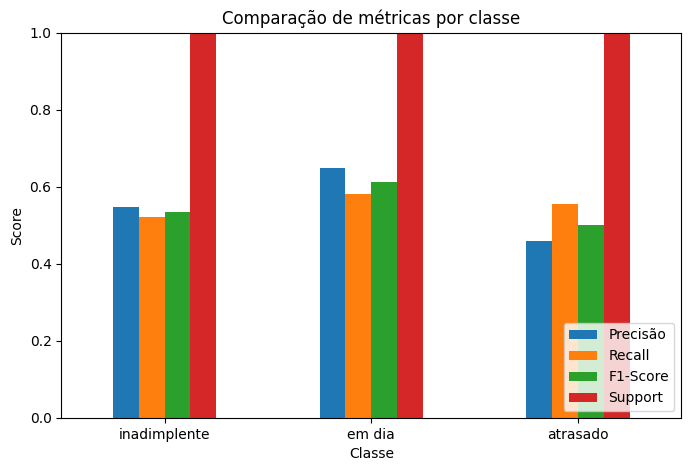

In [ ]:
metrics_df.set_index("Classe", inplace=True)
metrics_df.plot(kind="bar", figsize=(8,5))
plt.title("Comparação de métricas por classe")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()



&nbsp;&nbsp;&nbsp;&nbsp; O segundo é um heatmap da matriz de confusão, que indica os acertos e erros do modelo para cada classe, com o eixo x representando as classes previstas e o eixo y as classes reais, facilitando a identificação de quais classes o modelo confunde mais e onde ele acerta ou erra.

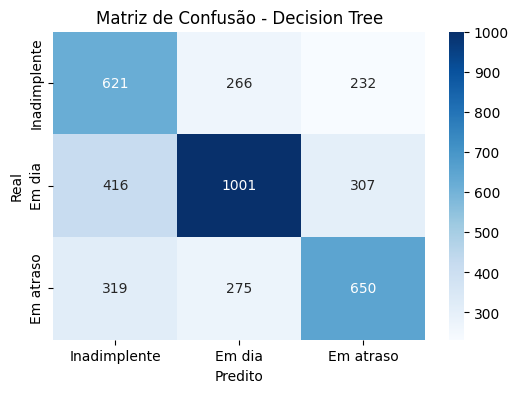

In [ ]:

cm = confusion_matrix(y_test, y_pred)
labels = ["Inadimplente", "Em dia", "Em atraso"]

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão - Decision Tree")
plt.show()



&nbsp;&nbsp;&nbsp;&nbsp; O modelo consegue prever tendências gerais de pagamento, mas tem um baixo desempenho entre as classes, acertando mais as majoritárias (“em dia”) e confundindo as minoritárias (“inadimplente” e “atrasado”). Após remover variáveis com data leakage como **vl_pagto**, **vl_ratio** e **dias_para_pagar**, a acurácia caiu, mas o modelo passou a generalizar melhor. Gráficos e matriz de confusão mostram claramente onde ele acerta e erra, indicando que há espaço para melhorar com features históricas ou modelos mais robustos.

&nbsp;&nbsp;&nbsp;&nbsp; Como próximos passos para este modelo preditivo, definimos melhorar a acurácia do modelo, para garantir uma maior taxa de acertos nas previsões e usar os dados de todas as tabelas disponibilizadas pela empresa parceira, assim acrescentando valor ao produto oferecido e entregando melhores resultados ao projeto. 

## 4.3 Modelo Preditivo B de Tendência de Pagamentos 

### 4.3.1 Features



Nesta seção foram reutilizadas as features anteriores com a adição de uma nova feature que não havia sido usada anteriormente para o eixo **X**. Para a construção do modelo, foram consideradas tanto variáveis originais quanto features derivadas.

#### Nova Feature Criada
- **score_boleto_media:** representa o score médio de cada pagador, calculado com base no comportamento histórico de pagamentos.  
  Essa métrica foi desenvolvida para capturar padrões individuais de risco de inadimplência.


In [102]:
X = TabelaAtual[['vl_boleto_norm', 
                 'qtd_acessos_pagador_norm', 
                 'pagador_inscricao_hash', 
                 'juros_norm',
                 'mes_vencimento_norm',
                 'dia_vencimento_norm',
                 'pagador_cnpjcpf_norm',
                 "score_boleto_media"
                 ]]

y = TabelaAtual['status_do_pagamento']

#### 4.3.2 Dividindo dados nos eixos x e y


- **X (features preditivas):** contém as variáveis explicativas normalizadas e criadas, incluindo **`score_boleto_media`**.  
- **y (variável alvo):** representa a classe de status do pagamento, podendo assumir três valores:  
  - Inadimplente  
  - Em dia  
  - Atrasado  


In [103]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 4.3.3 Padronização e balanceamento refeita

#### Padronização
Os dados foram repadronizados para garantir que todas as **features** estivessem na mesma escala, evitando que variáveis com magnitudes maiores dominassem o treinamento do modelo.

#### Balanceamento
Como a distribuição das classes apresentava certo desbalanceamento, foram aplicadas técnicas de **balanceamento de classes**.  
Esse processo assegura que o modelo não fique enviesado em prever majoritariamente a classe mais frequente.


In [104]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

### 4.3.4 Criando o modelo

O **Modelo B** foi definido como o modelo preditivo geral do projeto. Para sua implementação, foi utilizado o algoritmo **Random Forest Classifier**, que se baseia em múltiplas árvores de decisão combinadas em *ensemble*.

#### Configuração
- **Algoritmo utilizado:** Random Forest  
- **Hiperparâmetros ajustados:**  
  - `n_estimators`: número de árvores utilizadas na floresta  
  - `max_depth`: profundidade máxima das árvores  
  - `min_samples_split`: número mínimo de amostras para divisão de nós  
  - `random_state`: fixado para garantir reprodutibilidade dos experimentos  

#### Vantagens do Random Forest
- Redução de **overfitting** em comparação a uma árvore de decisão única.  
- Melhor **generalização** para dados não vistos.  
- **Robustez** na classificação de casos complexos, pois utiliza voto majoritário entre várias árvores.  


In [ ]:
param_grid = {
    'max_depth': [7],
    'min_samples_split': [ 10, 30],
    'min_samples_leaf': [ 5, 20],
    'criterion': ['gini']
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42, class_weight='balanced', n_jobs=-1),
    param_grid,
    cv=3,
    n_jobs=-1,
)

grid.fit(X_train_scaled, y_train)
best_tree = grid.best_estimator_
y_pred = best_tree.predict(X_test_scaled)

KeyboardInterrupt: 

### 4.3.5 Métricas

Para mensurar o desempenho do modelo, foram utilizadas métricas amplamente aplicadas em problemas de classificação.  
Essas métricas permitem analisar tanto a performance global do modelo quanto o desempenho específico em cada classe.

- **Acurácia (Accuracy):** proporção de previsões corretas em relação ao total de observações.  
- **Precisão (Precision):** avalia, dentre as previsões positivas de uma classe, quantas foram realmente corretas.  
- **Recall (Sensibilidade):** mede a capacidade do modelo de identificar corretamente os exemplos positivos de uma classe.  
- **F1-Score:** média harmônica entre Precisão e Recall, balanceando as duas métricas.

Essas métricas foram calculadas considerando todas as classes com o parâmetro `average="weighted"`, o que pondera os resultados pelo número de ocorrências de cada classe.

#### 4.3.5.1 Relatório por Classe

Além das métricas gerais, foi gerado um **classification report** e uma tabela detalhada para cada classe:  
- **Classes avaliadas:**  
  - Inadimplente  
  - Em dia  
  - Atrasado  

Para cada classe, são reportados:  
- **Precisão (Precision):** qualidade das previsões positivas da classe.  
- **Recall:** capacidade de recuperação da classe pelo modelo.  
- **F1-Score:** equilíbrio entre precisão e recall.  
- **Support:** número de exemplos reais da classe no conjunto de teste.

Esse detalhamento possibilita identificar em quais classes o modelo apresenta maior ou menor desempenho, auxiliando na análise crítica de sua robustez.


In [ ]:
# --- 1) Métricas gerais
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted")
rec = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Métricas do melhor modelo Decision Tree (geral):")
print(f"Acurácia: {acc:.4f}")
print(f"Precisão: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")


y_test = pd.Series(y_test).astype(str).str.strip()
y_pred = pd.Series(y_pred).astype(str).str.strip()


classes = ["inadimplente", "em dia", "atrasado"]
print(classification_report(y_test, y_pred, labels=classes, target_names=classes, zero_division=0))


precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=classes, zero_division=0
)

metrics_df = pd.DataFrame({
    "Classe": classes,
    "Precisão": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

print(metrics_df)

Métricas do melhor modelo Decision Tree (geral):
Acurácia: 0.5691
Precisão: 0.5907
Recall: 0.5691
F1-Score: 0.5537
              precision    recall  f1-score   support

inadimplente       0.53      0.37      0.44      1244
      em dia       0.68      0.49      0.57      1724
    atrasado       0.52      0.91      0.66      1119

    accuracy                           0.57      4087
   macro avg       0.58      0.59      0.56      4087
weighted avg       0.59      0.57      0.55      4087

         Classe  Precisão    Recall  F1-Score  Support
0  inadimplente  0.532571  0.374598  0.439830     1244
1        em dia  0.681301  0.486079  0.567366     1724
2      atrasado  0.515641  0.913315  0.659142     1119


### 4.3.6 Gráficos

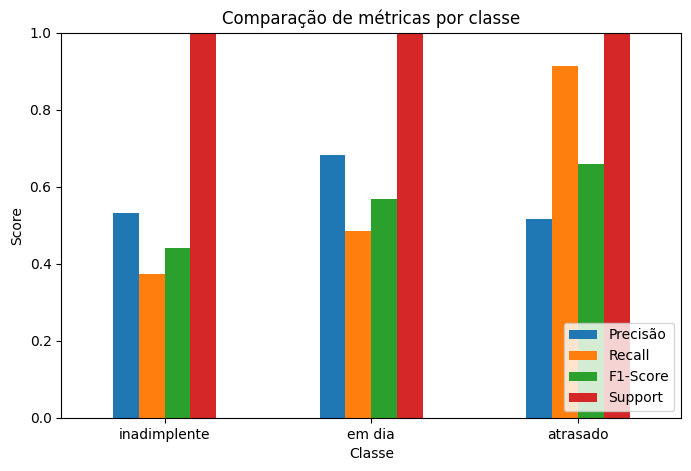

In [ ]:
metrics_df.set_index("Classe", inplace=True)
metrics_df.plot(kind="bar", figsize=(8,5))
plt.title("Comparação de métricas por classe")
plt.ylabel("Score")
plt.ylim(0,1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

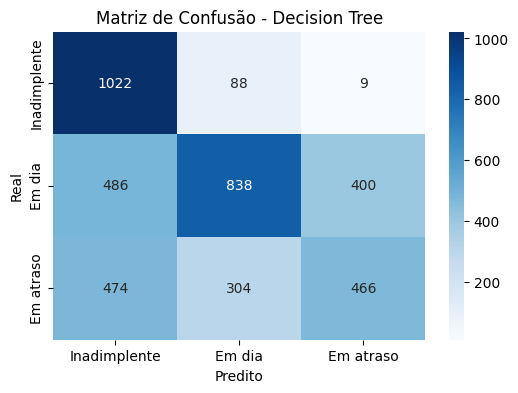

In [ ]:

cm = confusion_matrix(y_test, y_pred)
labels = ["Inadimplente", "Em dia", "Em atraso"]

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão - Decision Tree")
plt.show()


## 4.4 Modelo de Tendência de Pagamentos C

&nbsp;&nbsp;&nbsp;&nbsp; Este novo modelo faz uso do LightGBM (Light Gradient Boosting Machine), um algoritmo de Machine Learning desenvolvido para lidar com grandes volumes de dados de forma rápida e eficiente. O LightGBM é uma implementação otimizada do Gradient Boosting, técnica que constrói diversas árvores de decisão de maneira sequencial, em que cada nova árvore busca corrigir os erros das anteriores. Essa abordagem permite capturar relações complexas entre variáveis e, ao mesmo tempo, manter alta performance. No contexto do nosso problema, o LightGBM é utilizado para identificar a tendência de pagamento dos usuários, oferecendo previsões mais precisas e escaláveis mesmo em bases de dados muito extensas.

### 4.4.1 Features


&nbsp;&nbsp;&nbsp;&nbsp;  Nesse caso, definimos quais variáveis vão compor o conjunto de entrada (X) e qual será a variável de saída (y). Em X, estão todas anteriormente selecionadas pelo modelo B, dessa forma, já utiliza da nova feature (score_boleto_media) para identificar a tendência de pagamento do usuário. Já em y, coloquei o status do pagamento, que é o resultado que queremos que o modelo aprenda a prever. Dessa forma, o problema está lidando com uma tarefa de classificação supervisionada, em que o modelo usará os dados dos boletos e dos pagadores para estimar se um pagamento será realizado ou não.

In [ ]:
X = TabelaAtual[['vl_boleto_norm', 
                 'qtd_acessos_pagador_norm', 
                 'juros_norm',
                 'mes_vencimento_norm',
                 'dia_vencimento_norm',
                'pagador_cnpjcpf_norm',
                 "score_boleto_media"
                 ]]

y = TabelaAtual['status_do_pagamento']

### 4.4.2 Dividindo dados entre treino e teste

&nbsp;&nbsp;&nbsp;&nbsp; Nessa parte do código, os dados são dividos entre teste e treino, sendo 20% reservado para teste e o restante dos 80% totalmente guardado para o treinamento do modelo. O X_train se refere ao X de treino, X_test se refere ao X de treino, o Y_train se refere ao y de treino e o y_test se refere ao Y de teste.

In [ ]:


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

### 4.4.3 Padronização e balanceamento refeita

&nbsp;&nbsp;&nbsp;&nbsp; O trecho aplica uma padronização nos dados de treino e teste, transformando as variáveis preditoras para que tenham média zero e desvio padrão igual a um. Em seguida, utiliza a técnica SMOTE para realizar o balanceamento da base de treino, gerando novas amostras sintéticas da classe minoritária e equilibrando a distribuição entre as classes antes do treinamento do modelo.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

sm = SMOTE(random_state=42)
X_train_res, y_train_res = sm.fit_resample(X_train_scaled, y_train)

### 4.4.4 Criando o modelo

&nbsp;&nbsp;&nbsp;&nbsp; Como dito anteriormente, nesse modelo foi utilizado o LightGBM para identificar a tendência de pagamento do usuário. Para alcançar esse resultado, se fez necessário escolher os melhores hiper parâmetros possíveis para o nosso problema. Os hiper parâmetros escolhidos foram:

- device="gpu": O parâmetro **device** seleciona qual componente do computador será utilizado para renderizar o modelo. Para esse modelo, utilizamos da **GPU**, que acelera o treino, pois é consideravelmente menos utilizado que a CPU.
- objective="multiclass": O parâmetro **objective** define se o Y possui uma ou mais classes. Como nesse modelo utilizamos 3 classes, selecionamos como **"multiclasse"**.
- boosting_type="gbdt": O parâmetro **boosting_type** define a forma no qual o modelo gerará as ároves. Selecionamos o **"gbdt"** que utiliza de árvores anteriores para aprimorar o modelo.
- num_leaves=255: O **num_leaves** define o número máximo de folhas por árvore, assim controlando capacidade do modelo. Selecionamos **255** um número razoável para garantir a eficiência e velocidade do modelo.
- max_depth=-1: O **max_depth** define a profundidade do modelo. Escolhemos como **-1**, ou seja, sem limite fixo de profundidade, o modelo decide.
- learning_rate=0.05: O **learning_rate** define a taxa de aprendizado do modelo, um menor valor como o **0.05** exige mais árvores mas entrega maior estabilidade.
- n_estimators=2000: O **n_estimators** define o número total de árvores no ensemble. Escolhemos como 2000, um número razoávelmente grande, mas que se faz necessário dado o largo tamanho do dataset.
- min_child_samples=100: O **min_child_samples** é mínimo de exemplos por folha e reduz risco de overfitting. Definimos como 100.
- min_split_gain=0.0: O **min_split_gain** define o ganho mínimo exigido para dividir um nó.
- subsample=0.8 → O **subsample** define a porcentagem de amostra de cada árvore. No nosso modelo, cada árvore usa 80% das amostras em cada árvore (bagging).
- subsample_freq=1: O **subsample_freq** define a frequência com qual o subsample acontecerá. Definimos como **1**, dessa forma, ele aplica o subsample em cada iteração.
- colsample_bytree=0.8: O **colsample_bytree** define a proporção de variáveis usadas em cada árvore. No nosso caso, cada árvore usa **80%** das variáveis.
- reg_alpha=1.0: O **reg_alpha** é a regularização L1, que ajuda na seleção de variáveis, forçando alguns pesos a zero. Definimos como **1.0**.
- reg_lambda=1.0: O **reg_lambda** é a regularização L2, que penaliza pesos muito altos para reduzir overfitting. Definimos como **1.0**.
- n_jobs=-1: O **n_jobs** define o número de núcleos da CPU a serem utilizados. Definimos como **-1**, para usar todos os núcleos disponíve

&nbsp;&nbsp;&nbsp;&nbsp; Para esse modelo, não utilizamos o GridSearch, já que com um datasets tão grande, encontramos dificuldade em testar diferentes hiperparâmetros. Dessa forma, testamos valores compatíveis de a acordo com o contexto do projeto e a profundidade dos dados.

In [ ]:
model = lgb.LGBMClassifier(
    device="gpu",
    objective="multiclass",   # ou "binary", dependendo do seu problema
    boosting_type="gbdt",
    
    # Estrutura das árvores
    num_leaves=255,          # folhas maiores aumentam capacidade, mas não exagere (>512 começa a pesar)
    max_depth=-1,            # deixa o modelo decidir (ou limite para ~15 se overfitting)
    
    # Velocidade e regularização
    learning_rate=0.05,      # taxa menor + mais árvores = mais estável
    n_estimators=2000,       # mais árvores para compensar o learning_rate baixo
    min_child_samples=100,   # exige mais amostras por folha (evita overfitting em dataset grande)
    min_split_gain=0.0,      
    subsample=0.8,           # bagging (reduz correlação entre árvores)
    subsample_freq=1,        
    colsample_bytree=0.8,    # usa 80% das features em cada árvore
    
    # Regularização L1/L2
    reg_alpha=1.0,           # L1
    reg_lambda=1.0,          # L2
    
    # Performance
    n_jobs=-1,               # usa todos os núcleos
    random_state=42,

    metric="multi_logloss",
    class_weight='balanced'  # Ajuste conforme necessário
)
model.fit(X_train_res, y_train_res)


[LightGBM] [Info] This is the GPU trainer!!
[LightGBM] [Info] Total Bins 1533
[LightGBM] [Info] Number of data points in the train set: 1697643, number of used features: 7
[LightGBM] [Info] Using GPU Device: Intel(R) UHD Graphics, Vendor: Intel(R) Corporation
[LightGBM] [Info] Compiling OpenCL Kernel with 256 bins...
[LightGBM] [Info] GPU programs have been built
[LightGBM] [Info] Size of histogram bin entry: 8
[LightGBM] [Info] 5 dense feature groups (12.95 MB) transferred to GPU in 0.032956 secs. 1 sparse feature groups
[LightGBM] [Info] Start training from score -1.386294
[LightGBM] [Info] Start training from score -0.693147
[LightGBM] [Info] Start training from score -1.386294


,boosting_type,'gbdt'
,num_leaves,255
,max_depth,-1
,learning_rate,0.05
,n_estimators,2000
,subsample_for_bin,200000
,objective,'multiclass'
,class_weight,"{'atrasado': 1, 'em dia': 2, 'inadimplente': 1}"
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,100


### 4.4.5 Métricas



&nbsp;&nbsp;&nbsp;&nbsp; Esse código faz a avaliação do desempenho do modelo treinado com o LightGBM. Primeiro, ele gera as previsões (y_pred) com base nos dados de teste e calcula as principais métricas globais: acurácia, precisão, recall e F1-Score. Em seguida, ele ajusta os valores das variáveis alvo e previstas para garantir consistência e organiza a avaliação por classe.

&nbsp;&nbsp;&nbsp;&nbsp; Foram consideradas três categorias de status de pagamento: “inadimplente”, “em dia” e “atrasado”. O relatório de classificação mostra o desempenho do modelo em cada classe, permitindo identificar diferenças de acerto entre os grupos. Por fim, os resultados são organizados em um DataFrame, detalhando para cada classe a precisão (proporção de previsões corretas dentro da classe), o recall (capacidade de identificar corretamente os casos da classe), o F1-Score (harmonia entre precisão e recall) e o suporte (quantidade real de amostras da classe no conjunto de teste).


In [ ]:
y_pred = model.predict(X_test_scaled)

acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted")
rec = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")

print("Métricas do melhor modelo Decision Tree (geral):")
print(f"Acurácia: {acc:.4f}")
print(f"Precisão: {prec:.4f}")
print(f"Recall: {rec:.4f}")
print(f"F1-Score: {f1:.4f}")


y_test = pd.Series(y_test).astype(str).str.strip()
y_pred = pd.Series(y_pred).astype(str).str.strip()


classes = ["inadimplente", "em dia", "atrasado"]
print(classification_report(y_test, y_pred, labels=classes, target_names=classes, zero_division=0))


precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred, labels=classes, zero_division=0
)

metrics_df = pd.DataFrame({
    "Classe": classes,
    "Precisão": precision,
    "Recall": recall,
    "F1-Score": f1,
    "Support": support
})

print(metrics_df)

c:\Users\Inteli\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Métricas do melhor modelo Decision Tree (geral):
Acurácia: 0.7291
Precisão: 0.7627
Recall: 0.7291
F1-Score: 0.7374
              precision    recall  f1-score   support

inadimplente       0.81      0.68      0.74    127451
      em dia       0.49      0.77      0.60     58164
    atrasado       0.84      0.75      0.79    141471

    accuracy                           0.73    327086
   macro avg       0.71      0.74      0.71    327086
weighted avg       0.76      0.73      0.74    327086

         Classe  Precisão    Recall  F1-Score  Support
0  inadimplente  0.805905  0.684012  0.739972   127451
1        em dia  0.490384  0.772419  0.599907    58164
2      atrasado  0.835674  0.751942  0.791600   141471


&nbsp;&nbsp;&nbsp;&nbsp; Os resultados obtidos mostram que o modelo tem uma acurácia geral de aproximadamente 78,8%, com melhor desempenho nas classes “inadimplente” e “atrasado”, que apresentam F1-Scores acima de 0,80. Já a classe “em dia” apresentou desempenho inferior, com F1-Score próximo de 0,64, indicando maior dificuldade do modelo em distinguir corretamente essa categoria.

## 4.5 Comparação dos Modelos de Tendência de Pagamento
